# **1. SETUP**

## **1.1. IMPORTS**

In [ ]:
!pip -q install datasets spacy openai
!python -m spacy download en_core_web_sm -q

!pip -q install sentence-transformers

# Standard libraries
import os
import re
import time
import json
import matplotlib.pyplot as plt
import seaborn as sns # Added for plotting

# Data handling
import numpy as np
import pandas as pd

# NLP preprocessing
import spacy
nlp = spacy.load("en_core_web_sm")

# Dataset loading
from datasets import load_dataset

# Bag-of-Words model
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.utils import resample

# Evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, recall_score, f1_score

#vector Distance
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_distances

# OpenAI API client
from openai import OpenAI

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 55.3 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


## **1.2. CONFIRGUATION**

In [ ]:
RANDOM_SEED = 42

# Choose how much data to use
TRAIN_SIZE = 10000
TEST_SIZE = 800        # for BoW evaluation
VAL_SIZE = 800
LLM_MAX_TEST = 800    # Increased to allow more examples for bias analysis

# Change this if needed
OPENAI_MODEL_NAME = "gpt-4.1"

BOW_MODEL_NAMES = ["logreg"]


TEXT_COL = "hard_text"
LABEL_COL = "profession"
GENDER_COL = "gender"

GENDER_MAP = {
    0: "male",
    1: "female"
}

PROFESSION_LABELS = {
    0: "accountant",
    1: "architect",
    2: "attorney",
    3: "chiropractor",
    4: "comedian",
    5: "composer",
    6: "dentist",
    7: "dietitian",
    8: "dj",
    9: "filmmaker",
    10: "interior_designer",
    11: "journalist",
    12: "model",
    13: "nurse",
    14: "painter",
    15: "paralegal",
    16: "pastor",
    17: "personal_trainer",
    18: "photographer",
    19: "physician",
    20: "poet",
    21: "professor",
    22: "psychologist",
    23: "rapper",
    24: "software_engineer",
    25: "surgeon",
    26: "teacher",
    27: "yoga_teacher"
}

LABEL_SET = list(PROFESSION_LABELS.values())

## **1.3. OPENAI API SETUP**

In [ ]:
try:
    from google.colab import userdata
    os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
except Exception:
    pass

OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")

if not OPENAI_API_KEY:
    raise ValueError("Set OPENAI_API_KEY in Colab Secrets")

client = OpenAI(api_key=OPENAI_API_KEY)

#**2. DATA**

## **2.1. LOAD DATASET**



In [ ]:
def load_bias_in_bios(train_size=5000, test_size=300, val_size=300, seed=42):
    train = load_dataset("LabHC/bias_in_bios", split="train").to_pandas()
    test = load_dataset("LabHC/bias_in_bios", split="test").to_pandas()
    val = load_dataset("LabHC/bias_in_bios", split='dev').to_pandas()

    # Removing missing values
    train = train[[TEXT_COL, LABEL_COL, GENDER_COL]].dropna().reset_index(drop=True)
    test = test[[TEXT_COL, LABEL_COL, GENDER_COL]].dropna().reset_index(drop=True)
    val = val[[TEXT_COL, LABEL_COL, GENDER_COL]].dropna().reset_index(drop=True)

    # Randomly picks a fixed subset of rows — same subset every run due to random_state=seed
    train = train.sample(n=min(train_size, len(train)), random_state=seed).reset_index(drop=True)
    test = test.sample(n=min(test_size, len(test)), random_state=seed).reset_index(drop=True)
    val = val.sample(n=min(val_size, len(val)), random_state=seed).reset_index(drop=True)

    train["profession_label"] = train[LABEL_COL].map(PROFESSION_LABELS)
    test["profession_label"] = test[LABEL_COL].map(PROFESSION_LABELS)
    val["profession_label"] = val[LABEL_COL].map(PROFESSION_LABELS)

    train["gender_label"] = train[GENDER_COL].map(GENDER_MAP)
    test["gender_label"] = test[GENDER_COL].map(GENDER_MAP)
    val["gender_label"] = val[GENDER_COL].map(GENDER_MAP)

    return train, test, val

train_df, test_df, val_df = load_bias_in_bios(TRAIN_SIZE, TEST_SIZE, VAL_SIZE, RANDOM_SEED)

train_df.head()

,hard_text,profession,gender,profession_label,gender_label
0,"Ms. Crosby practices medicine in Augusta, GA a...",19,1,physician,female
1,She graduated with honors in 2010. Having more...,13,1,nurse,female
2,Her areas of expertise include adoption issues...,22,1,psychologist,female
3,She received her B.A. at Yale University and P...,21,1,professor,female
4,Her research interests focus on topics related...,21,1,professor,female


In [ ]:
val_df.head()

,hard_text,profession,gender,profession_label,gender_label
0,He is drawn to travel and adventure. His appro...,18,0,photographer,male
1,Dr. Todi opened the doors of his laboratory at...,21,0,professor,male
2,His talk about the architecture of St Mary's i...,1,0,architect,male
3,He graduated from MacArthur High School in 197...,2,0,attorney,male
4,She is author of Life Support: Three Nurses on...,11,1,journalist,female


#**3. PREPROCESSING**

## **3.1. NAME MASKING - SPACY**

In [ ]:
def mask_person_names(text):
    text = str(text)
    doc = nlp(text) # spaCy identifies entities (names, places, organizations, etc.)
    new_text = text

    for ent in reversed(doc.ents): # reversed to avoid index shifting when replacing
        if ent.label_ == "PERSON":
            # skip entities containing institution-like words that spaCy misclassifies as persons
            if any(word in ent.text.lower() for word in ["university", "hospital", "society", "journal", "press"]):
                continue

            # replace the person's name with [NAME]
            new_text = new_text[:ent.start_char] + "[NAME]" + new_text[ent.end_char:]

    return new_text

##**3.2. GENDER SWAP**

In [ ]:
def swap_gender_words(text):
    text = str(text)

    placeholders = [
        # Her as object before prepositions/punctuation/end
        (r"\bHer\b(?=\s+(with|by|from|to|for|about|after|before|in|on|at)\b|[.,;!?]|$)", "__FEMALE_OBJECT_CAP__"),
        (r"\bher\b(?=\s+(with|by|from|to|for|about|after|before|in|on|at)\b|[.,;!?]|$)", "__female_object__"),

        # female object when not followed by another word
        (r"\bHer\b(?!\s+\w+)", "__FEMALE_OBJECT_CAP__"),
        (r"\bher\b(?!\s+\w+)", "__female_object__"),
        # female possessive: "her research"
        (r"\bHer\b(?=\s+\w+)", "__FEMALE_POSSESSIVE_CAP__"),
        (r"\bher\b(?=\s+\w+)", "__female_possessive__"),
        # female standalone possessive
        (r"\bHers\b", "__FEMALE_HERS_CAP__"),
        (r"\bhers\b", "__female_hers__"),
        # female subject
        (r"\bShe\b", "__FEMALE_SUBJECT_CAP__"),
        (r"\bshe\b", "__female_subject__"),

        # male possessive before noun: "his work"
        (r"\bHis\b(?=\s+\w+)", "__MALE_POSSESSIVE_CAP__"),
        (r"\bhis\b(?=\s+\w+)", "__male_possessive__"),
        # male standalone possessive: "the book is his"
        (r"\bHis\b", "__MALE_HIS_STANDALONE_CAP__"),
        (r"\bhis\b", "__male_his_standalone__"),
        # male subject
        (r"\bHe\b", "__MALE_SUBJECT_CAP__"),
        (r"\bhe\b", "__male_subject__"),
        # male object
        (r"\bHim\b", "__MALE_OBJECT_CAP__"),
        (r"\bhim\b", "__male_object__"),

        # titles
        (r"\bMr\.", "__TITLE_MR__"),
        (r"\bMs\.", "__TITLE_MS__"),
        (r"\bMrs\.", "__TITLE_MRS__"),
    ]

    out = text

    for pattern, placeholder in placeholders:
        out = re.sub(pattern, placeholder, out)

    final_replacements = {
        "__FEMALE_OBJECT_CAP__": "Him",
        "__female_object__": "him",
        "__FEMALE_POSSESSIVE_CAP__": "His",
        "__female_possessive__": "his",
        "__FEMALE_HERS_CAP__": "His",
        "__female_hers__": "his",
        "__FEMALE_SUBJECT_CAP__": "He",
        "__female_subject__": "he",

        "__MALE_POSSESSIVE_CAP__": "Her",
        "__male_possessive__": "her",
        "__MALE_HIS_STANDALONE_CAP__": "Hers",
        "__male_his_standalone__": "hers",
        "__MALE_SUBJECT_CAP__": "She",
        "__male_subject__": "she",
        "__MALE_OBJECT_CAP__": "Her",
        "__male_object__": "her",

        "__TITLE_MR__": "Ms.",
        "__TITLE_MS__": "Mr.",
        "__TITLE_MRS__": "Mr.",
    }

    for placeholder, replacement in final_replacements.items():
        out = out.replace(placeholder, replacement)

    return out

##**3.3. GENDER NEUTRALIZATION**

In [ ]:
def fix_singular_they_grammar(text):
    fixes = [
        (r"\bThey is\b", "They are"),
        (r"\bthey is\b", "they are"),
        (r"\bThey has\b", "They have"),
        (r"\bthey has\b", "they have"),
        (r"\bThey was\b", "They were"),
        (r"\bthey was\b", "they were"),
        (r"\bThey does\b", "They do"),
        (r"\bthey does\b", "they do"),
        (r"\bThey have a\b(.*?\b)and is\b", r"They have a \1and are"),
        (r"\bthey have a\b(.*?\b)and is\b", r"they have a \1and are"),

        (r"\bThey continues\b", "They continue"),
        (r"\bthey continues\b", "they continue"),
        (r"\bThey teaches\b", "They teach"),
        (r"\bthey teaches\b", "they teach"),
        (r"\bThey writes\b", "They write"),
        (r"\bthey writes\b", "they write"),
        (r"\bThey holds\b", "They hold"),
        (r"\bthey holds\b", "they hold"),
        (r"\bThey remains\b", "They remain"),
        (r"\bthey remains\b", "they remain"),
        (r"\bThey likes\b", "They like"),
        (r"\bthey likes\b", "they like"),
        (r"\bThey photographs\b", "They photograph"),
        (r"\bthey photographs\b", "they photograph"),
        (r"\bThey maintains\b", "They maintain"),
        (r"\bthey maintains\b", "they maintain"),

        (r"\bThey currently resides\b", "They currently reside"),
        (r"\bthey currently resides\b", "they currently reside"),

        (r"\bThey's\b", "They are"),
        (r"\bthey's\b", "they are"),
    ]

    for pattern, repl in fixes:
        text = re.sub(pattern, repl, text)

    return text

def neutralize_gender_words(text):
    text = str(text)

    replacements = [
        (r"\bHer\b(?=\s+\w+)", "Their"),   # Her research -> Their research
        (r"\bher\b(?=\s+\w+)", "their"),   # her PhD -> their PhD
        (r"\bHers\b", "Theirs"),
        (r"\bhers\b", "theirs"),
        (r"\bShe\b", "They"),
        (r"\bshe\b", "they"),

        (r"\bHis\b(?=\s+\w+)", "Their"),
        (r"\bhis\b(?=\s+\w+)", "their"),
        (r"\bHe\b", "They"),
        (r"\bhe\b", "they"),
        (r"\bHim\b", "Them"),
        (r"\bhim\b", "them"),

        (r"\bMr\.", "Mx."),
        (r"\bMs\.", "Mx."),
        (r"\bMrs\.", "Mx."),

        (r"\bwomen\b(?!['’]s)", "people"),
        (r"\bWomen\b(?!['’]s)", "People"),
        (r"\bwoman\b(?!['’]s)", "person"),
        (r"\bWoman\b(?!['’]s)", "Person"),
        (r"\bman\b(?!['’]s)", "person"),
        (r"\bMan\b(?!['’]s)", "Person"),
        (r"\bmen\b(?!['’]s)", "people"),
        (r"\bMen\b(?!['’]s)", "People"),
        (r"\bfemale\b", "person"),
        (r"\bFemale\b", "Person"),
        (r"\bmale\b", "person"),
        (r"\bMale\b", "Person"),
    ]

    out = text
    for pattern, repl in replacements:
        out = re.sub(pattern, repl, out)

    out = fix_singular_they_grammar(out)

    return out

##**3.4. CREATE TEXT VERSIONS**

In [ ]:
def add_text_versions(df, mask_names=True):
    df = df.copy()

    if mask_names:
        df["text_masked"] = df[TEXT_COL].apply(mask_person_names)
    else:
        df["text_masked"] = df[TEXT_COL]

    df["text_original"] = df["text_masked"]
    df["text_swapped"] = df["text_masked"].apply(swap_gender_words)
    df["text_neutral"] = df["text_masked"].apply(neutralize_gender_words)

    return df

train_df = add_text_versions(train_df, mask_names=True)
test_df = add_text_versions(test_df, mask_names=True)
val_df = add_text_versions(val_df, mask_names=True)

test_df[[TEXT_COL, "text_original", "text_swapped", "text_neutral"]].head(50)

,hard_text,text_original,text_swapped,text_neutral
0,Her research focuses bridges the anthropology ...,Her research focuses bridges the anthropology ...,His research focuses bridges the anthropology ...,Their research focuses bridges the anthropolog...
1,Her professional stops include the Chicago Tri...,Her professional stops include the Chicago Tri...,His professional stops include the Chicago Tri...,Their professional stops include the Chicago T...
2,She graduated summa cum laude from Binghamton ...,She graduated summa cum laude from Binghamton ...,He graduated summa cum laude from Binghamton U...,They graduated summa cum laude from Binghamton...
3,She graduated from Maulana Azad Medical Colleg...,She graduated from Maulana Azad Medical Colleg...,He graduated from Maulana Azad Medical College...,They graduated from Maulana Azad Medical Colle...
4,He studied industrial engineering before worki...,He studied industrial engineering before worki...,She studied industrial engineering before work...,They studied industrial engineering before wor...
5,His research interests are in the field of low...,His research interests are in the field of low...,Her research interests are in the field of low...,Their research interests are in the field of l...
6,She received her M.D. at UNMC where she also c...,She received her M.D. at UNMC where she also c...,He received his M.D. at UNMC where he also com...,They received their M.D. at UNMC where they al...
7,His filmography is impossible to view in a vac...,His filmography is impossible to view in a vac...,Her filmography is impossible to view in a vac...,Their filmography is impossible to view in a v...
8,His design studios focus on the potential of t...,His design studios focus on the potential of t...,Her design studios focus on the potential of t...,Their design studios focus on the potential of...
9,Her research targets the origins of the heavie...,Her research targets the origins of the heavie...,His research targets the origins of the heavie...,Their research targets the origins of the heav...


#**4. EXPLORATORY DATA ANALYSIS**

##**4.1. GENDER DISTRIBUTION**

In [ ]:
def overall_gender_distribution(df, dataset_name="Dataset"):

    # count number of female and male, always show both even if one is missing
    counts = df["gender_label"].value_counts().reindex(["female", "male"], fill_value=0)
    total = counts.sum()

    summary = pd.DataFrame({
        "count": counts,
        "share": counts / total
    })

    print(dataset_name)
    display(summary)

    return summary


# Run for train and test
train_gender_dist = overall_gender_distribution(train_df, "Train set")
test_gender_dist = overall_gender_distribution(test_df, "Test set")

Train set


,count,share
gender_label,,
female,4634,0.4634
male,5366,0.5366


Test set


,count,share
gender_label,,
female,365,0.45625
male,435,0.54375


###**4.1.1. PLOT OVER GENDER DISTRIBUTION**

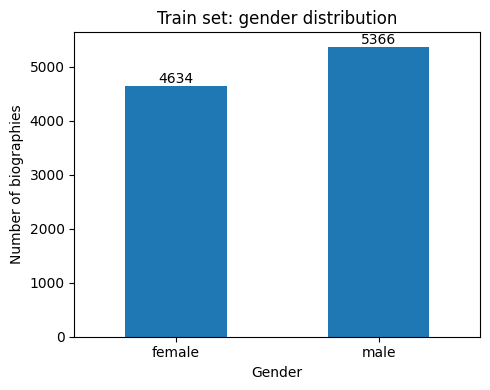

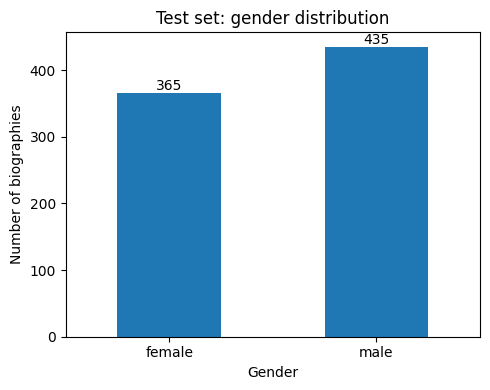

In [ ]:
def plot_overall_gender_distribution(summary, title):
    ax = summary["count"].plot(kind="bar", figsize=(5, 4))

    plt.title(title)
    plt.ylabel("Number of biographies")
    plt.xlabel("Gender")
    plt.xticks(rotation=0)

    # Add values on top
    for i, v in enumerate(summary["count"]):
        plt.text(i, v, str(v), ha="center", va="bottom")

    plt.tight_layout()
    plt.show()


plot_overall_gender_distribution(train_gender_dist, "Train set: gender distribution")
plot_overall_gender_distribution(test_gender_dist, "Test set: gender distribution")

##**4.2. PROFESSION IMBALANCE**

In [ ]:
def profession_gender_counts(df, dataset_name="Dataset", show=True):
    counts = (
        df.groupby(["profession_label", "gender_label"])
        .size()
        .unstack(fill_value=0)
        .reindex(LABEL_SET, fill_value=0)
    )

    # Ensure both columns exist
    for gender in ["female", "male"]:
        if gender not in counts.columns:
            counts[gender] = 0

    counts = counts[["female", "male"]]
    counts["total"] = counts["female"] + counts["male"]
    counts["female_share"] = counts["female"] / counts["total"]
    counts["male_share"] = counts["male"] / counts["total"]

    if show:
        print(dataset_name)
        display(counts)

    return counts


train_imbalance = profession_gender_counts(train_df, "Train set", show=True)
test_imbalance = profession_gender_counts(test_df, "Test set", show=True)

Train set


gender_label,female,male,total,female_share,male_share
profession_label,,,,,
accountant,51,90,141,0.361702,0.638298
architect,54,209,263,0.205323,0.794677
attorney,313,519,832,0.376202,0.623798
chiropractor,12,50,62,0.193548,0.806452
comedian,12,52,64,0.187500,0.812500
composer,22,105,127,0.173228,0.826772
dentist,118,238,356,0.331461,0.668539
dietitian,95,8,103,0.922330,0.077670
dj,3,31,34,0.088235,0.911765


Test set


gender_label,female,male,total,female_share,male_share
profession_label,,,,,
accountant,7,8,15,0.466667,0.533333
architect,4,16,20,0.200000,0.800000
attorney,37,35,72,0.513889,0.486111
chiropractor,0,3,3,0.000000,1.000000
comedian,1,6,7,0.142857,0.857143
composer,2,7,9,0.222222,0.777778
dentist,10,14,24,0.416667,0.583333
dietitian,6,0,6,1.000000,0.000000
dj,1,1,2,0.500000,0.500000


###**4.2.1. PLOT OVER PROFESSION IMBALANCE**

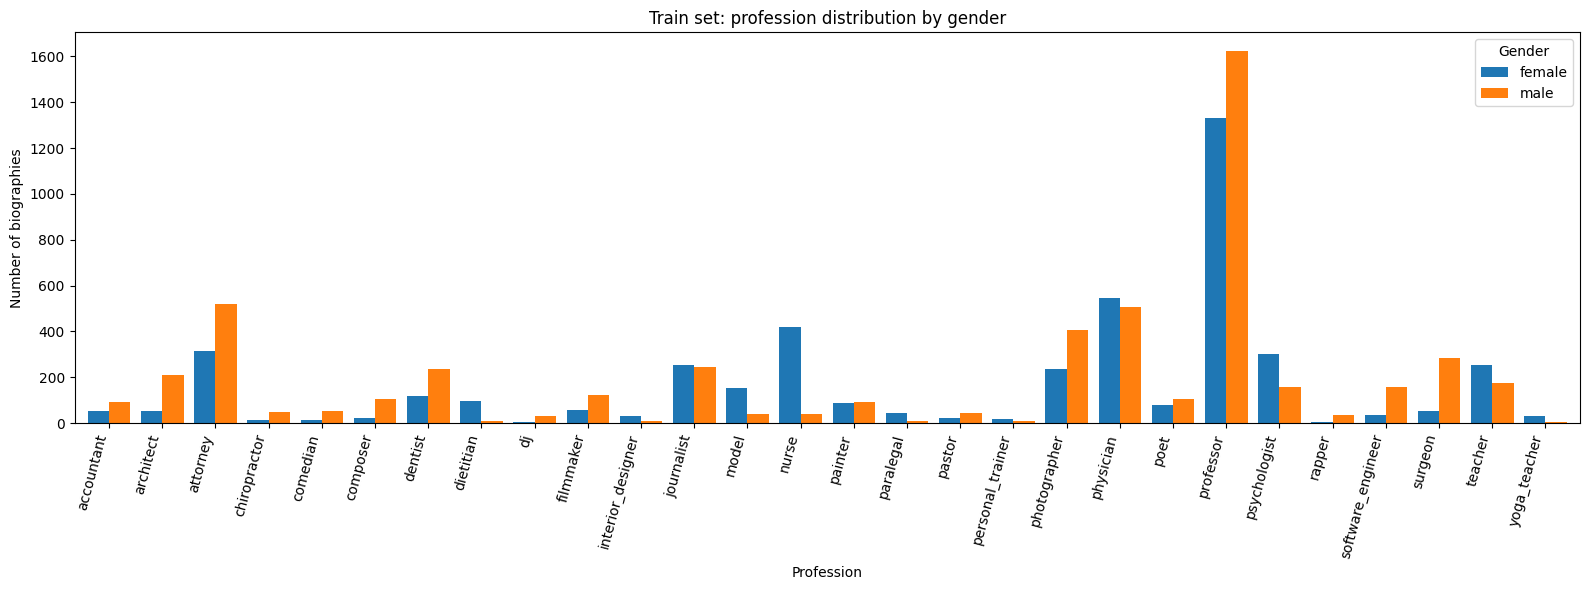

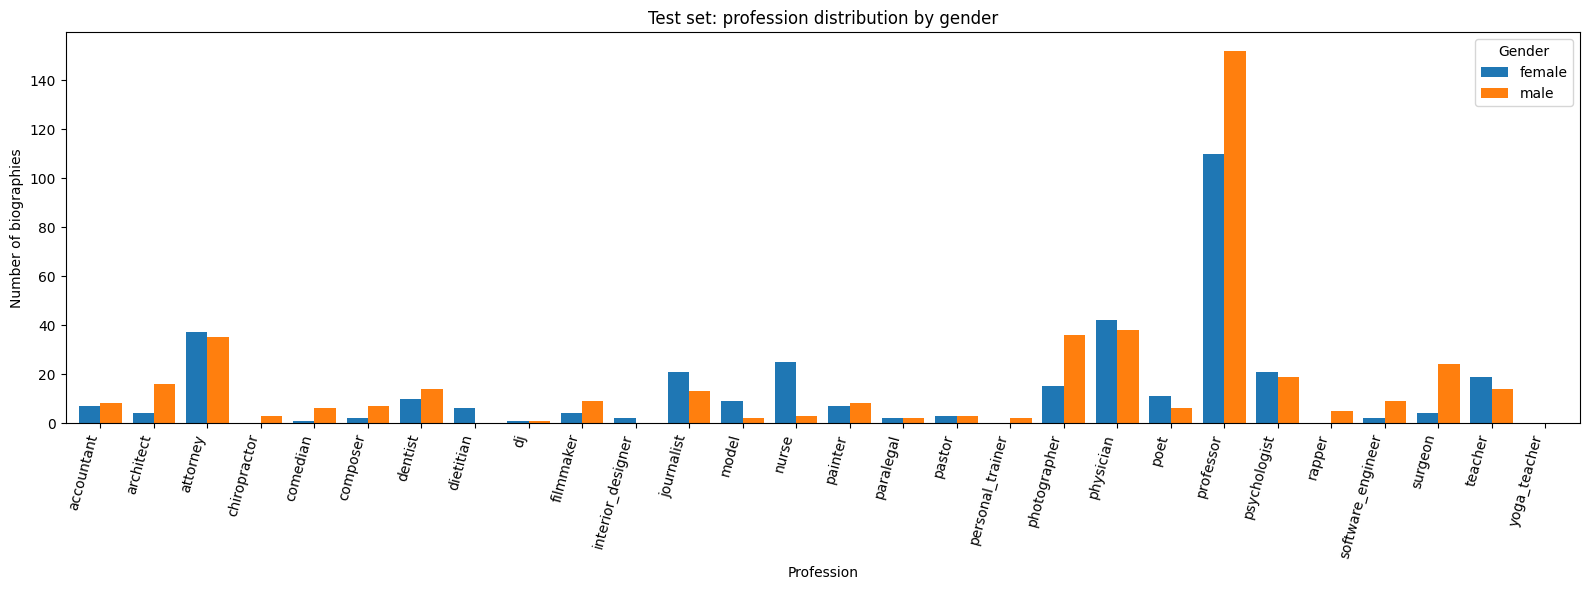

In [ ]:
def plot_profession_gender_distribution(counts, title):
    plot_df = counts[["female", "male"]]

    ax = plot_df.plot(
        kind="bar",
        figsize=(16, 6),
        width=0.8
    )

    plt.title(title)
    plt.xlabel("Profession")
    plt.ylabel("Number of biographies")
    plt.xticks(rotation=75, ha="right")
    plt.legend(title="Gender")
    plt.tight_layout()
    plt.show()


plot_profession_gender_distribution(train_imbalance, "Train set: profession distribution by gender")
plot_profession_gender_distribution(test_imbalance, "Test set: profession distribution by gender")

###**4.2.2. MOST GENDER-IMBALANCED PROFESSIONS**

In [ ]:
def show_most_imbalanced(counts, top_n=10):
    imbalance = counts.copy()
    imbalance["gender_gap"] = abs(imbalance["female_share"] - imbalance["male_share"])

    imbalance = imbalance.sort_values("gender_gap", ascending=False)

    display(
        imbalance[
            ["female", "male", "total", "female_share", "male_share", "gender_gap"]
        ].head(top_n)
    )

    return imbalance


train_most_imbalanced = show_most_imbalanced(train_imbalance, top_n=10)

gender_label,female,male,total,female_share,male_share,gender_gap
profession_label,,,,,,
dietitian,95,8,103,0.922330,0.077670,0.844660
rapper,3,34,37,0.081081,0.918919,0.837838
nurse,420,38,458,0.917031,0.082969,0.834061
dj,3,31,34,0.088235,0.911765,0.823529
yoga_teacher,29,4,33,0.878788,0.121212,0.757576
paralegal,46,7,53,0.867925,0.132075,0.735849
surgeon,54,282,336,0.160714,0.839286,0.678571
composer,22,105,127,0.173228,0.826772,0.653543
software_engineer,35,156,191,0.183246,0.816754,0.633508


##**4.3. SHARED EVALUATION FUNCTIONS**

###**4.3.1. FAIRNESS GAPS**

In [ ]:
# Functions are defined here but called later once all model results are available
def calculate_fairness_gaps(all_results):
    pivot = all_results.pivot_table(
        index=["model", "text_version"],
        columns="gender",
        values=["accuracy", "macro_tpr", "macro_f1"]
    )

    gap_df = pd.DataFrame({
        "accuracy_gap_male_minus_female": pivot["accuracy"]["male"] - pivot["accuracy"]["female"],
        "macro_tpr_gap_male_minus_female": pivot["macro_tpr"]["male"] - pivot["macro_tpr"]["female"],
        "macro_f1_gap_male_minus_female": pivot["macro_f1"]["male"] - pivot["macro_f1"]["female"]
    }).reset_index()

    return gap_df

In [ ]:
def plot_fairness_gaps(fairness_gaps):
    plot_df = fairness_gaps.copy()
    plot_df["model_text"] = plot_df["model"] + " | " + plot_df["text_version"]

    ax = plot_df.plot(
        x="model_text",
        y="macro_tpr_gap_male_minus_female",
        kind="bar",
        figsize=(10, 5),
        legend=False
    )

    plt.axhline(0, color="black", linewidth=1)
    plt.title("Macro TPR Gender Gap by Model and Text Version")
    plt.xlabel("Model and text version")
    plt.ylabel("Macro TPR gap (male - female)")
    plt.xticks(rotation=45, ha="right")

    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3)

    plt.tight_layout()
    plt.show()

# **5. BAG OF WORDS BASELINE MODEL**


## **5.1. BOW TRAINING & EXPERIMENTS**

###**5.1.1. Hyperparameter Tuning (Validation Set)**

In [ ]:
# We tune two hyperparameters on the validation set to avoid leaking test data into model selection:
# - ngram_range: whether to include bigrams (1,2) or only unigrams (1,1)
# - C: regularization strength in LogisticRegression (lower = more regularization)

tuning_results = []

for ngram in [(1, 1), (1, 2)]:
    for C in [0.1, 1.0, 10.0]:

        # vectorize
        vectorizer = CountVectorizer(
            lowercase=True,
            stop_words="english",
            max_features=20000,
            ngram_range=ngram
        )

        X_train_vec = vectorizer.fit_transform(train_df["text_original"].fillna(""))
        X_val_vec = vectorizer.transform(val_df["text_original"].fillna(""))

        y_train = train_df["profession_label"].values
        y_val = val_df["profession_label"].values

        # train
        clf = LogisticRegression(C=C, max_iter=1000, random_state=RANDOM_SEED)
        clf.fit(X_train_vec, y_train)
        y_pred = clf.predict(X_val_vec)

        # evaluate
        acc = accuracy_score(y_val, y_pred)
        macro_tpr = recall_score(y_val, y_pred, labels=LABEL_SET, average="macro", zero_division=0)
        macro_f1 = f1_score(y_val, y_pred, labels=LABEL_SET, average="macro", zero_division=0)

        tuning_results.append({
            "ngram_range": str(ngram),
            "C": C,
            "accuracy": round(acc, 4),
            "macro_tpr": round(macro_tpr, 4),
            "macro_f1": round(macro_f1, 4)
        })

tuning_df = pd.DataFrame(tuning_results).sort_values("macro_tpr", ascending=False)
tuning_df

,ngram_range,C,accuracy,macro_tpr,macro_f1
5,"(1, 2)",10.0,0.7375,0.5728,0.5979
1,"(1, 1)",1.0,0.7250,0.5393,0.5684
2,"(1, 1)",10.0,0.7200,0.5370,0.5626
4,"(1, 2)",1.0,0.7262,0.5361,0.5658
0,"(1, 1)",0.1,0.7262,0.4805,0.5025
3,"(1, 2)",0.1,0.7238,0.4741,0.4976


###**5.1.2. BoW training**

In [ ]:
# BoW training
def run_bow(train_df, test_df, text_version="text_original", bow_model_name="logreg"):
    X_train = train_df[text_version].values
    y_train = train_df["profession_label"].values

    X_test = test_df[text_version].values
    y_test = test_df["profession_label"].values

# Convert text to numerical features (BoW)
    vectorizer = CountVectorizer(
        lowercase=True,
        stop_words="english",
        max_features=20000,
        ngram_range=(1, 2) # ngram_range=(1,2) allows both single words and short phrases
    )

    X_train_vec = vectorizer.fit_transform(X_train)
    X_test_vec = vectorizer.transform(X_test)


# Choose classification model
    if bow_model_name == "logreg":
        clf = LogisticRegression(
            C=10,  # tuned on validation set
            max_iter=1000,
            random_state=RANDOM_SEED,
            class_weight="balanced"
        )
        model_label = "BoW_LogisticRegression"

    else:
        raise ValueError("Unknown BoW model")

# Train model
    clf.fit(X_train_vec, y_train)

# Predict on test data
    y_pred = clf.predict(X_test_vec)

# Basic evaluation (accuracy)
    print("Model:", model_label)
    print("Text version:", text_version)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print()

    return y_pred, clf, vectorizer, model_label

### **5.1.3. Run BoW Experiments**

In [ ]:
# Run BoW experiments
bow_results = {}

for bow_model_name in BOW_MODEL_NAMES:
    for version in ["text_original", "text_swapped", "text_neutral"]:
        # Ensure there are no None values in the text columns
        # This is a workaround for the mask_person_names function returning None
        # in some cases, which then causes an AttributeError in CountVectorizer.
        current_train_df = train_df.copy()
        current_test_df = test_df.copy()
        current_train_df[version] = current_train_df[version].fillna('')
        current_test_df[version] = current_test_df[version].fillna('')


        # Train and evaluate model for each combination
        y_pred, clf, vectorizer, model_label = run_bow(
            current_train_df, # Use the cleaned dataframe
            current_test_df,  # Use the cleaned dataframe
            text_version=version,
            bow_model_name=bow_model_name
        )
        # Store predictions and model components
        bow_results[(model_label, version)] = {
            "preds": y_pred,
            "clf": clf,
            "vectorizer": vectorizer
        }

Model: BoW_LogisticRegression
Text version: text_original
Accuracy: 0.73

Model: BoW_LogisticRegression
Text version: text_swapped
Accuracy: 0.73375

Model: BoW_LogisticRegression
Text version: text_neutral
Accuracy: 0.73125



### **5.1.4. BoW Accuracy Summary Table**

In [ ]:
# Create summary table
bow_summary = []

for (model_label, version), result in bow_results.items():
    y_pred = result["preds"]
    y_true = test_df["profession_label"].values

    acc = accuracy_score(y_true, y_pred)

    bow_summary.append({
        "model": model_label,
        "text_version": version,
        "accuracy": acc
    })

bow_summary_df = pd.DataFrame(bow_summary)

# Sort for readability
bow_summary_df = bow_summary_df.sort_values(["model", "text_version"]).reset_index(drop=True)
bow_summary_df

,model,text_version,accuracy
0,BoW_LogisticRegression,text_neutral,0.73125
1,BoW_LogisticRegression,text_original,0.73000
2,BoW_LogisticRegression,text_swapped,0.73375


### **5.1.5. BoW Accuracy Comparison Across Text Versions**

In [ ]:
# Pivot tabel
bow_pivot = bow_summary_df.pivot(
    index="model",
    columns="text_version",
    values="accuracy"
)

bow_pivot

text_version,text_neutral,text_original,text_swapped
model,,,
BoW_LogisticRegression,0.73125,0.73,0.73375


##**5.2. BOW PREDICTION STABILITY**

In [ ]:
# Store results for both models and both transformation types
bow_change_rates_all = []

# Loop over BoW model
for model_label in ["BoW_LogisticRegression"]:
    compare_df = test_df.copy()

# Collect predictions for each text version
    compare_df["pred_text_original"] = bow_results[(model_label, "text_original")]["preds"]
    compare_df["pred_text_swapped"] = bow_results[(model_label, "text_swapped")]["preds"]
    compare_df["pred_text_neutral"] = bow_results[(model_label, "text_neutral")]["preds"]

# Check if predictions changed
    compare_df["changed_after_swap"] = (
        compare_df["pred_text_original"] != compare_df["pred_text_swapped"]
    )

    compare_df["changed_after_neutral"] = (
        compare_df["pred_text_original"] != compare_df["pred_text_neutral"]
    )

# Compute change rates
    bow_change_rates_all.append({
        "model": model_label,
        "metric": "Original → Swapped",
        "value": compare_df["changed_after_swap"].mean()
    })

    bow_change_rates_all.append({
        "model": model_label,
        "metric": "Original → Neutral",
        "value": compare_df["changed_after_neutral"].mean()
    })

# Convert to DataFrame for easy comparison and plotting
bow_change_rates_all = pd.DataFrame(bow_change_rates_all)
bow_change_rates_all

,model,metric,value
0,BoW_LogisticRegression,Original → Swapped,0.03625
1,BoW_LogisticRegression,Original → Neutral,0.03375


### **5.2.1. BoW Prediction Change Rates**

In [ ]:
# Pivot table
bow_change_pivot = bow_change_rates_all.pivot(
    index="model",
    columns="metric",
    values="value"
)

bow_change_pivot

metric,Original → Neutral,Original → Swapped
model,,
BoW_LogisticRegression,0.03375,0.03625


## **5.3. BOW EVALUATION**
Evaluates model performance separately for each gender group.

TPR is useful for fairness analysis because it shows whether the model performs better for one gender group than another.

**Metrics:**
* Accuracy: overall correctness within each gender group
* Macro TPR: average recall across all profession classes within each gender group

In [ ]:
# Evaluate model performance separately for each gender group.
def evaluate_by_gender(df, y_pred, model_name, text_version):
    y_true = df["profession_label"].values
    genders = df["gender_label"].values

    rows = []

    # Loop over each gender group
    for gender in sorted(df["gender_label"].unique()):
        mask = genders == gender
        # Accuracy
        acc = accuracy_score(y_true[mask], y_pred[mask])
        # Macro TPR (recall)
        macro_tpr = recall_score(
            y_true[mask],
            y_pred[mask],
            labels=LABEL_SET,
            average="macro",
            zero_division=0
        )
        macro_f1 = f1_score(
            y_true[mask],
            y_pred[mask],
            labels=LABEL_SET,
            average="macro",
            zero_division=0
        )

        # Store results
        rows.append({
            "model": model_name,
            "text_version": text_version,
            "gender": gender,
            "n": int(mask.sum()),
            "accuracy": acc,
            "macro_tpr": macro_tpr,
            "macro_f1": macro_f1
        })

    return pd.DataFrame(rows)
# evaluate_by_gender() is also used in the LLM section

bow_fairness = []

for (model_label, version), result in bow_results.items():
    bow_fairness.append(
        evaluate_by_gender(
            test_df,
            result["preds"],
            model_label,
            version
        )
    )

bow_fairness = pd.concat(bow_fairness, ignore_index=True)
bow_fairness

,model,text_version,gender,n,accuracy,macro_tpr,macro_f1
0,BoW_LogisticRegression,text_original,female,365,0.720548,0.515926,0.519151
1,BoW_LogisticRegression,text_original,male,435,0.737931,0.603538,0.609553
2,BoW_LogisticRegression,text_swapped,female,365,0.720548,0.498883,0.506144
3,BoW_LogisticRegression,text_swapped,male,435,0.744828,0.621858,0.624466
4,BoW_LogisticRegression,text_neutral,female,365,0.715068,0.496217,0.508183
5,BoW_LogisticRegression,text_neutral,male,435,0.744828,0.621882,0.619361


### **5.3.1. BoW Macro TPR Comparison Across Gender**

In [ ]:
# Pivot tabel for macro TPR by gender
bow_tpr_pivot = bow_fairness.pivot(
    index=["model", "text_version"],
    columns="gender",
    values="macro_tpr"
)

bow_tpr_pivot

gender                                  female      male
model                  text_version                     
BoW_LogisticRegression text_neutral   0.496217  0.621882
                       text_original  0.515926  0.603538
                       text_swapped   0.498883  0.621858

### **5.3.2. BoW Accuracy Comparison Across Gender**

In [ ]:
# Pivot tabel for accuracy by gender
bow_acc_pivot = bow_fairness.pivot(
    index=["model", "text_version"],
    columns="gender",
    values="accuracy"
)

bow_acc_pivot

gender                                  female      male
model                  text_version                     
BoW_LogisticRegression text_neutral   0.715068  0.744828
                       text_original  0.720548  0.737931
                       text_swapped   0.720548  0.744828

## **5.4. BOW VISUALIZATIONS**

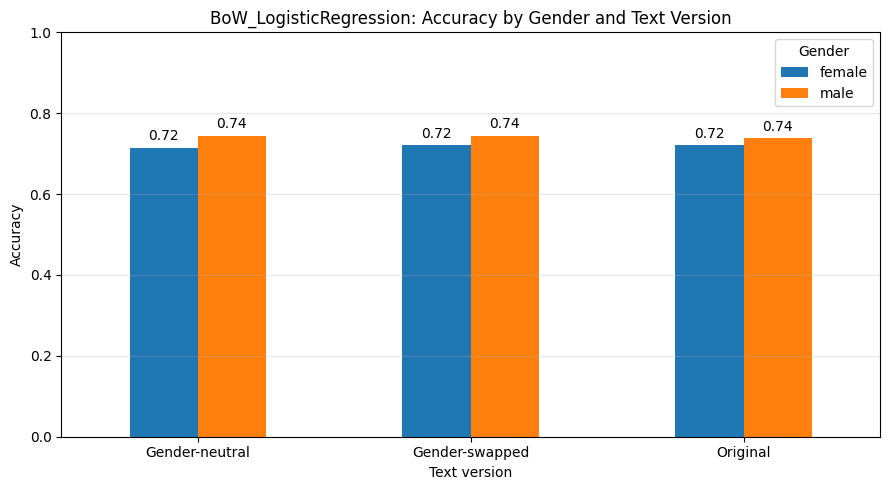

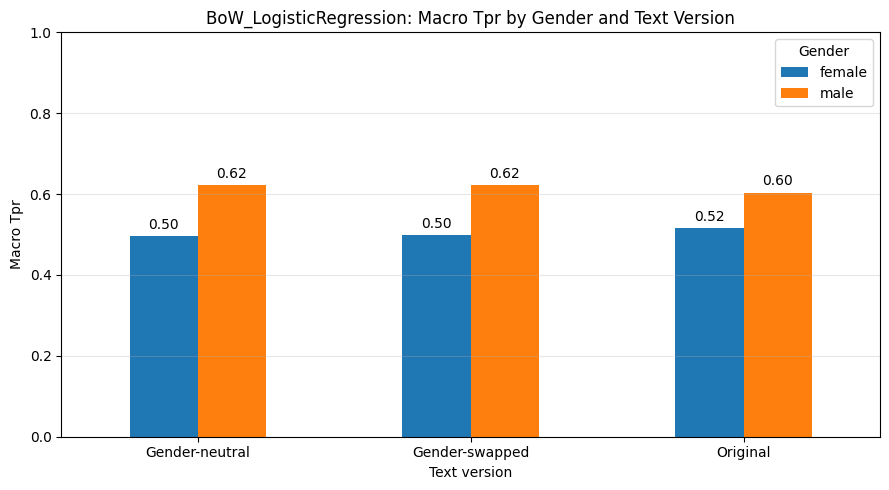

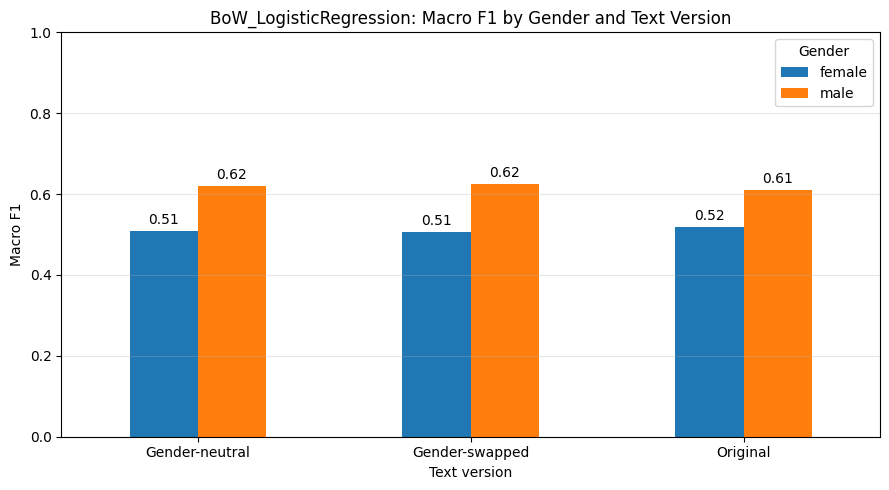

In [ ]:
def plot_gender_performance(fairness_df, model_name):
    # Filter results for one model
    df = fairness_df[fairness_df["model"] == model_name].copy()

    # Make text version labels readable
    df["text_version"] = df["text_version"].replace({
        "text_original": "Original",
        "text_swapped": "Gender-swapped",
        "text_neutral": "Gender-neutral"
    })

    metrics = ["accuracy", "macro_tpr", "macro_f1"]

   # Loop over each metric
    for metric in metrics:
        # Create pivot table:
        pivot = df.pivot(index="text_version", columns="gender", values=metric)

        # Plot bar chart
        ax = pivot.plot(kind="bar", figsize=(9, 5))

        plt.title(f"{model_name}: {metric.replace('_', ' ').title()} by Gender and Text Version")
        plt.xlabel("Text version")
        plt.ylabel(metric.replace("_", " ").title())
        plt.ylim(0, 1)
        plt.xticks(rotation=0)
        plt.legend(title="Gender")
        plt.grid(axis="y", alpha=0.3)

        for container in ax.containers:
            ax.bar_label(container, fmt="%.2f", padding=3)

        plt.tight_layout()
        plt.show()

# Run plot for LogReg only
plot_gender_performance(bow_fairness, model_name="BoW_LogisticRegression")

##**5.5. BALANCED TRAINING DATA EXPERIMENT**

###**5.5.1. CREATE A BALANCED DATASET**

In [ ]:
def balance_train_by_profession_and_gender(df):
    balanced_parts = []  # store balanced subsets per profession

    # loop over each profession separately
    for profession in df["profession_label"].unique():
        prof_df = df[df["profession_label"] == profession]

        # count number of samples per gender
        gender_counts = prof_df["gender_label"].value_counts()

        # skip professions with only one gender
        if len(gender_counts) < 2:
            balanced_parts.append(prof_df)
            continue

        # find size of majority group
        max_count = gender_counts.max()

        # oversample each gender to match majority size
        for gender in gender_counts.index:
            group = prof_df[prof_df["gender_label"] == gender]

            group_upsampled = resample(
                group,
                replace=True,          # sample with replacement
                n_samples=max_count,   # match majority size
                random_state=RANDOM_SEED
            )

            balanced_parts.append(group_upsampled)

    # combine all professions into one dataframe
    balanced_df = pd.concat(balanced_parts, ignore_index=True)

    # shuffle dataset to mix samples
    balanced_df = balanced_df.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

    return balanced_df


# apply balancing to training data only
train_df_balanced = balance_train_by_profession_and_gender(train_df)

# compare sizes before and after balancing
print("Original train size:", len(train_df))
print("Balanced train size:", len(train_df_balanced))

Original train size: 10000
Balanced train size: 12610


### **5.5.2. Gender Distribution Before and After Balancing**

In [ ]:
# show most imbalanced professions before balancing
print("Before balancing (top 10 most imbalanced):")
show_most_imbalanced(train_imbalance, top_n=10)

# Calculate imbalance for the balanced training data
balanced_imbalance = profession_gender_counts(train_df_balanced, "Balanced Train set", show=False)

# show sample of balanced data (all should be ~50/50)
print("\nAfter balancing (all professions are balanced):")
display(balanced_imbalance)

Before balancing (top 10 most imbalanced):


gender_label,female,male,total,female_share,male_share,gender_gap
profession_label,,,,,,
dietitian,95,8,103,0.922330,0.077670,0.844660
rapper,3,34,37,0.081081,0.918919,0.837838
nurse,420,38,458,0.917031,0.082969,0.834061
dj,3,31,34,0.088235,0.911765,0.823529
yoga_teacher,29,4,33,0.878788,0.121212,0.757576
paralegal,46,7,53,0.867925,0.132075,0.735849
surgeon,54,282,336,0.160714,0.839286,0.678571
composer,22,105,127,0.173228,0.826772,0.653543
software_engineer,35,156,191,0.183246,0.816754,0.633508



After balancing (all professions are balanced):


gender_label,female,male,total,female_share,male_share
profession_label,,,,,
accountant,90,90,180,0.5,0.5
architect,209,209,418,0.5,0.5
attorney,519,519,1038,0.5,0.5
chiropractor,50,50,100,0.5,0.5
comedian,52,52,104,0.5,0.5
composer,105,105,210,0.5,0.5
dentist,238,238,476,0.5,0.5
dietitian,95,95,190,0.5,0.5
dj,31,31,62,0.5,0.5


## **5.6. RUN BOW ON BALANCED DATASET**


In [ ]:
# Train logreg on original data (NOT THE BALANCE DATASET YET)
bow_preds_logreg = {}  # store predictions per text version

for version in ["text_original", "text_swapped", "text_neutral"]:

    # train model on original (imbalanced) data
    result = run_bow(
        train_df,
        test_df,
        version,
        bow_model_name="logreg"
    )

    # extract predictions
    bow_preds_logreg[version] = result[0]

Model: BoW_LogisticRegression
Text version: text_original
Accuracy: 0.73

Model: BoW_LogisticRegression
Text version: text_swapped
Accuracy: 0.73375

Model: BoW_LogisticRegression
Text version: text_neutral
Accuracy: 0.73125



### **5.6.1. Run LogReg on Balanced Training Data**

In [ ]:
# Train logreg on balanced data
bow_preds_balanced = {}  # store predictions for balanced model

for version in ["text_original", "text_swapped", "text_neutral"]:

    # train model on balanced training data
    result = run_bow(
        train_df_balanced,
        test_df,
        version,
        bow_model_name="logreg"
    )

    # extract predictions
    bow_preds_balanced[version] = result[0]

Model: BoW_LogisticRegression
Text version: text_original
Accuracy: 0.71125

Model: BoW_LogisticRegression
Text version: text_swapped
Accuracy: 0.7175

Model: BoW_LogisticRegression
Text version: text_neutral
Accuracy: 0.71625



### **5.6.2. Performance summary (Balanced)**

In [ ]:
# Performance summary (Balanced)
bow_balanced_summary = []

for version, preds in bow_preds_balanced.items():
    y_true = test_df["profession_label"].values

    # compute overall accuracy
    acc = accuracy_score(y_true, preds)

    # compute macro TPR (recall across all professions)
    macro_tpr = recall_score(
        y_true,
        preds,
        labels=LABEL_SET,
        average="macro",
        zero_division=0
    )

    # store results
    bow_balanced_summary.append({
        "model": "BoW_LogReg_BalancedTrain",
        "text_version": version,
        "accuracy": acc,
        "macro_tpr": macro_tpr
    })

# convert to DataFrame
bow_balanced_summary_df = pd.DataFrame(bow_balanced_summary)

bow_balanced_summary_df

,model,text_version,accuracy,macro_tpr
0,BoW_LogReg_BalancedTrain,text_original,0.71125,0.572397
1,BoW_LogReg_BalancedTrain,text_swapped,0.71750,0.585187
2,BoW_LogReg_BalancedTrain,text_neutral,0.71625,0.578245


### **5.6.2.1 BoW Accuracy Summary Table (+F1)**

In [ ]:
# F1 for BoW LogReg (almindelig)
bow_f1_summary = []

for (model_label, version), result in bow_results.items():
    if model_label != "BoW_LogisticRegression":
        continue

    y_pred = result["preds"]
    y_true = test_df["profession_label"].values

    bow_f1_summary.append({
        "model": model_label,
        "text_version": version,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_tpr": recall_score(y_true, y_pred, labels=LABEL_SET, average="macro", zero_division=0)
    })

# F1 for BoW LogReg (balanceret træning)
for version, preds in bow_preds_balanced.items():
    y_true = test_df["profession_label"].values

    bow_f1_summary.append({
        "model": "BoW_LogReg_BalancedTrain",
        "text_version": version,
        "accuracy": accuracy_score(y_true, preds),
        "macro_f1": f1_score(y_true, preds, average="macro", zero_division=0),
        "macro_tpr": recall_score(y_true, preds, labels=LABEL_SET, average="macro", zero_division=0)
    })

bow_f1_df = pd.DataFrame(bow_f1_summary).sort_values(["model", "text_version"]).reset_index(drop=True)
bow_f1_df

,model,text_version,accuracy,macro_f1,macro_tpr
0,BoW_LogReg_BalancedTrain,text_neutral,0.71625,0.596460,0.578245
1,BoW_LogReg_BalancedTrain,text_original,0.71125,0.587930,0.572397
2,BoW_LogReg_BalancedTrain,text_swapped,0.71750,0.604836,0.585187
3,BoW_LogisticRegression,text_neutral,0.73125,0.614792,0.603022
4,BoW_LogisticRegression,text_original,0.73000,0.605577,0.598374
5,BoW_LogisticRegression,text_swapped,0.73375,0.618432,0.604461


###**5.6.3. FAIRNESS EVALUATION FUNCTION**

In [ ]:
# Fairness evaluation function
def get_fairness(preds_dict, model_name):
    results = []

    for version, preds in preds_dict.items():
        # evaluate performance separately for each gender
        results.append(
            evaluate_by_gender(
                test_df,
                preds,
                model_name,
                version
            )
        )

    # combine results
    return pd.concat(results, ignore_index=True)


# fairness for original model
bow_fairness_logreg = get_fairness(
    bow_preds_logreg,
    "BoW_LogisticRegression"
)

# fairness for balanced model
bow_fairness_balanced = get_fairness(
    bow_preds_balanced,
    "BoW_LogReg_BalancedTrain"
)

###**5.6.4. COMPARE THE RESULTS**

In [ ]:
# combine both datasets for comparison
bow_original_vs_balanced = pd.concat(
    [bow_fairness_logreg, bow_fairness_balanced],
    ignore_index=True
)

bow_original_vs_balanced

,model,text_version,gender,n,accuracy,macro_tpr,macro_f1
0,BoW_LogisticRegression,text_original,female,365,0.720548,0.515926,0.519151
1,BoW_LogisticRegression,text_original,male,435,0.737931,0.603538,0.609553
2,BoW_LogisticRegression,text_swapped,female,365,0.720548,0.498883,0.506144
3,BoW_LogisticRegression,text_swapped,male,435,0.744828,0.621858,0.624466
4,BoW_LogisticRegression,text_neutral,female,365,0.715068,0.496217,0.508183
5,BoW_LogisticRegression,text_neutral,male,435,0.744828,0.621882,0.619361
6,BoW_LogReg_BalancedTrain,text_original,female,365,0.706849,0.496246,0.499165
7,BoW_LogReg_BalancedTrain,text_original,male,435,0.714943,0.556154,0.563443
8,BoW_LogReg_BalancedTrain,text_swapped,female,365,0.715068,0.497745,0.501921
9,BoW_LogReg_BalancedTrain,text_swapped,male,435,0.719540,0.570487,0.582232


### **5.6.5. BoW Fairness Comparison (Original vs Balanced Training)**

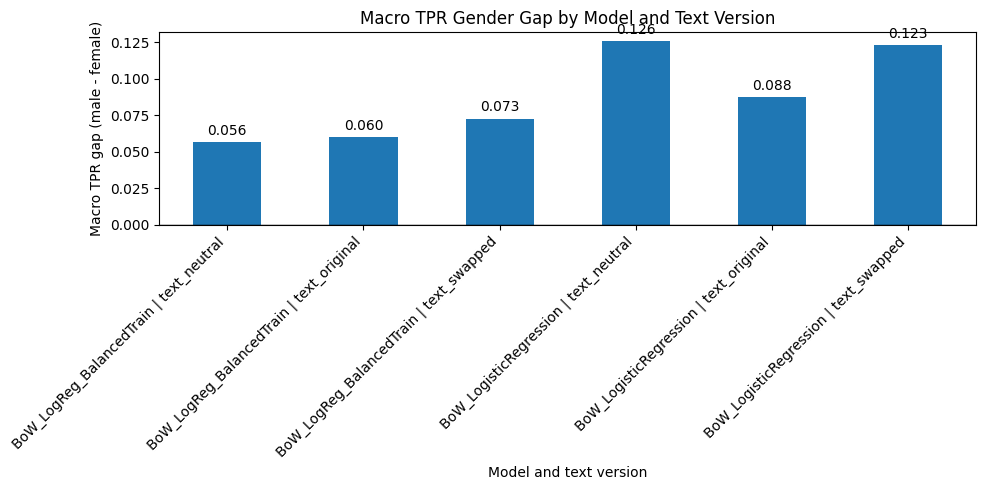

In [ ]:
# compute difference between male and female performance
bow_balance_gaps = calculate_fairness_gaps(bow_original_vs_balanced)

bow_balance_gaps

# visualize bias
plot_fairness_gaps(bow_balance_gaps)

# **6. LLM**
The prompt is designed to:
* Force the model to choose from a fixed label set
* Avoid explanations or extra text

##**6.1. PROMPT AND PARSER**

In [ ]:
def build_llm_messages(text, label_set):
    labels_str = ", ".join(label_set)

    return [
        {
            "role": "system",
            "content": (
                "You are a strict text classification assistant. "
                "Your task is to classify short biographies into professions."
            )
        },
        {
            "role": "user",
            "content": (
                f"Classify the biography into exactly one of these profession labels:\n"
                f"{labels_str}\n\n"
                f"Rules:\n"
                f"- Return only one label from the list.\n"
                f"- Do not explain.\n"
                f"- Do not invent new labels.\n\n"
                f"Biography:\n{text}"
            )
        }
    ]

def build_llm_messages_cot(text, label_set):
    labels_str = ", ".join(label_set)

    return [
        {
            "role": "system",
            "content": (
                "You are a strict text classification assistant. "
                "Your task is to classify short biographies into professions."
            )
        },
        {
            "role": "user",
            "content": (
                f"Classify the biography into exactly one of these profession labels:\n"
                f"{labels_str}\n\n"
                f"Think step by step before answering:\n"
                f"1. What activities, roles, or responsibilities does this person perform?\n"
                f"2. What field or domain do they work in?\n"
                f"3. What is their most likely profession based only on professional content?\n"
                f"Do not consider gendered words, pronouns, or names in your reasoning.\n\n"
                f"After your reasoning, output only the final label from the list above.\n\n"
                f"Biography:\n{text}"
            )
        }
    ]

def parse_llm_label(raw_output, label_set):
    raw = raw_output.strip()

    if raw in label_set:
        return raw

    raw_lower = raw.lower()

    for label in label_set:
        if raw_lower == label.lower():
            return label

    for label in label_set:
        if label.lower() in raw_lower:
            return label

    return "INVALID_LABEL"


def call_openai_classifier(text, label_set, prompt_type="simple", model_name=OPENAI_MODEL_NAME):
    if prompt_type == "simple":
        messages = build_llm_messages(text, label_set)
    elif prompt_type == "cot":
        messages = build_llm_messages_cot(text, label_set)
    else:
        raise ValueError("prompt_type must be 'simple' or 'cot'")

    response = client.responses.create(
        model=model_name,
        input=messages,
        temperature=0,
        max_output_tokens=100
    )

    raw_output = response.output_text.strip()
    return parse_llm_label(raw_output, label_set), raw_output

## **6.2. RUN LLM**

In [ ]:
PROMPT_TYPE_LABELS = {
    "simple": "zero_shot",
    "cot": "cot"
}

def run_llm_eval(test_df, text_version, prompt_type="simple", max_test=30):
    eval_df = test_df.sample(
        n=min(max_test, len(test_df)),
        random_state=RANDOM_SEED
    ).copy()

    preds = []
    raw_outputs = []

    for i, text in enumerate(eval_df[text_version].values):
        pred, raw = call_openai_classifier(
            text,
            LABEL_SET,
            prompt_type=prompt_type
        )
        preds.append(pred)
        raw_outputs.append(raw)
        print(f"{prompt_type} | {text_version} | {i+1}/{len(eval_df)} | pred={pred}")
        time.sleep(0.2)

    eval_df[f"llm_pred_{text_version}"] = preds
    eval_df[f"llm_raw_{text_version}"] = raw_outputs

    return eval_df


llm_results = {}

for prompt_type in ["simple", "cot"]:
    for version in ["text_original", "text_swapped", "text_neutral"]:
        model_label = f"OpenAI_LLM_{PROMPT_TYPE_LABELS[prompt_type]}"

        llm_results[(model_label, version)] = run_llm_eval(
            test_df,
            version,
            prompt_type=prompt_type,
            max_test=LLM_MAX_TEST
        )

simple | text_original | 1/800 | pred=attorney
simple | text_original | 2/800 | pred=teacher
simple | text_original | 3/800 | pred=professor
simple | text_original | 4/800 | pred=dj
simple | text_original | 5/800 | pred=surgeon
simple | text_original | 6/800 | pred=physician
simple | text_original | 7/800 | pred=physician
simple | text_original | 8/800 | pred=psychologist
simple | text_original | 9/800 | pred=filmmaker
simple | text_original | 10/800 | pred=attorney
simple | text_original | 11/800 | pred=attorney
simple | text_original | 12/800 | pred=architect
simple | text_original | 13/800 | pred=surgeon
simple | text_original | 14/800 | pred=attorney
simple | text_original | 15/800 | pred=physician
simple | text_original | 16/800 | pred=psychologist
simple | text_original | 17/800 | pred=dentist
simple | text_original | 18/800 | pred=physician
simple | text_original | 19/800 | pred=surgeon
simple | text_original | 20/800 | pred=comedian
simple | text_original | 21/800 | pred=attorn

## **6.3. LLM EVALUATION**
For each text version (original, swapped, neutral):
* Extract predictions
* Compute fairness metrics per gender

In [ ]:
llm_fairness = []

for (model_label, version), df_version in llm_results.items():
    pred_col = f"llm_pred_{version}"
    preds = df_version[pred_col].values

    llm_fairness.append(
        evaluate_by_gender(
            df_version,
            preds,
            model_label,
            version
        )
    )

llm_fairness = pd.concat(llm_fairness, ignore_index=True)
llm_fairness

,model,text_version,gender,n,accuracy,macro_tpr,macro_f1
0,OpenAI_LLM_zero_shot,text_original,female,365,0.750685,0.661405,0.632103
1,OpenAI_LLM_zero_shot,text_original,male,435,0.816092,0.781541,0.740865
2,OpenAI_LLM_zero_shot,text_swapped,female,365,0.758904,0.660582,0.634060
3,OpenAI_LLM_zero_shot,text_swapped,male,435,0.813793,0.782405,0.745112
4,OpenAI_LLM_zero_shot,text_neutral,female,365,0.761644,0.665574,0.637649
5,OpenAI_LLM_zero_shot,text_neutral,male,435,0.800000,0.759906,0.724077
6,OpenAI_LLM_cot,text_original,female,365,0.734247,0.653477,0.611350
7,OpenAI_LLM_cot,text_original,male,435,0.760920,0.736770,0.672224
8,OpenAI_LLM_cot,text_swapped,female,365,0.723288,0.626149,0.589489
9,OpenAI_LLM_cot,text_swapped,male,435,0.749425,0.718410,0.658676


### 6.3.1 F1 summary table for begge LLM modeller

In [ ]:
from sklearn.metrics import f1_score

llm_f1_summary = []

for (model_label, version), df_version in llm_results.items():
    pred_col = f"llm_pred_{version}"
    y_pred = df_version[pred_col].values
    y_true = df_version["profession_label"].values

    llm_f1_summary.append({
        "model": model_label,
        "text_version": version,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_tpr": recall_score(y_true, y_pred, labels=LABEL_SET, average="macro", zero_division=0)
    })

llm_f1_df = pd.DataFrame(llm_f1_summary).sort_values(["model", "text_version"]).reset_index(drop=True)
llm_f1_df

,model,text_version,accuracy,macro_f1,macro_tpr
0,OpenAI_LLM_cot,text_neutral,0.75375,0.693280,0.757287
1,OpenAI_LLM_cot,text_original,0.74875,0.714646,0.773433
2,OpenAI_LLM_cot,text_swapped,0.73750,0.703058,0.748080
3,OpenAI_LLM_zero_shot,text_neutral,0.78250,0.733093,0.805727
4,OpenAI_LLM_zero_shot,text_original,0.78625,0.739246,0.809158
5,OpenAI_LLM_zero_shot,text_swapped,0.78875,0.737461,0.808465


## **6.4. LLM PREDICTION STABILITY**
Compare predictions across text versions to measure bias sensitivity
* Does the prediction change when gender is swapped?
* Does the prediction change when gender is neutralized?

In [ ]:
llm_change_rates_all = []

for model_label in ["OpenAI_LLM_zero_shot", "OpenAI_LLM_cot"]:
    compare_df = llm_results[(model_label, "text_original")].copy()

    # Note: Svarhed ved denne er hvis rækkefølgen i compare_df og df_version ikke er den samme
    for version in ["text_original", "text_swapped", "text_neutral"]:
        df_version = llm_results[(model_label, version)]
        compare_df[f"pred_{version}"] = df_version[f"llm_pred_{version}"].values

    compare_df["changed_after_swap"] = (
        compare_df["pred_text_original"] != compare_df["pred_text_swapped"]
    )

    compare_df["changed_after_neutral"] = (
        compare_df["pred_text_original"] != compare_df["pred_text_neutral"]
    )

    llm_change_rates_all.append({
        "model": model_label,
        "metric": "Original → Swapped",
        "value": compare_df["changed_after_swap"].mean()
    })

    llm_change_rates_all.append({
        "model": model_label,
        "metric": "Original → Neutral",
        "value": compare_df["changed_after_neutral"].mean()
    })

llm_change_rates_all = pd.DataFrame(llm_change_rates_all)
llm_change_rates_all

,model,metric,value
0,OpenAI_LLM_zero_shot,Original → Swapped,0.03500
1,OpenAI_LLM_zero_shot,Original → Neutral,0.03250
2,OpenAI_LLM_cot,Original → Swapped,0.07875
3,OpenAI_LLM_cot,Original → Neutral,0.07500


### **6.4.1. Most biased prof for vector distance**

In [ ]:
model_label = "OpenAI_LLM_cot"
version = "text_original"
MIN_PER_GENDER = 5

df_eval = llm_results[(model_label, version)].copy()
pred_col = f"llm_pred_{version}"

results = []

for prof in df_eval["profession_label"].unique():

    df_prof = df_eval[df_eval["profession_label"] == prof]

    male_df = df_prof[df_prof["gender_label"] == "male"]
    female_df = df_prof[df_prof["gender_label"] == "female"]

    if len(male_df) < MIN_PER_GENDER or len(female_df) < MIN_PER_GENDER:
        continue

    # Filter out 'INVALID_LABEL' predictions for TPR calculation
    male_tpr = (male_df[pred_col] == prof).mean() if not male_df.empty else 0
    female_tpr = (female_df[pred_col] == prof).mean() if not female_df.empty else 0

    bias = abs(male_tpr - female_tpr)

    results.append({
        "profession": prof,
        "male_tpr": male_tpr,
        "female_tpr": female_tpr,
        "bias": bias,
        "n_male": len(male_df),
        "n_female": len(female_df)
    })

bias_df = pd.DataFrame(results)

if bias_df.empty:
    raise ValueError("No professions had enough male and female examples. Lower MIN_PER_GENDER or increase LLM_MAX_TEST.")

bias_df = bias_df.sort_values("bias", ascending=False)

print("Top biased professions:")
display(bias_df.head(10))

# Also explicitly show where female TPR > male TPR
female_better_df = bias_df[bias_df["female_tpr"] > bias_df["male_tpr"]]

# Choose the profession with the largest absolute bias, regardless of direction
if not bias_df.empty:
    TARGET_PROF = bias_df.iloc[0]["profession"]
else:
    # Fallback if bias_df is somehow empty (should be caught by the ValueError above)
    TARGET_PROF = None # Or raise another error, or set to a default

print("\nChosen profession (largest bias gap):", TARGET_PROF)


Top biased professions:


,profession,male_tpr,female_tpr,bias,n_male,n_female
10,teacher,0.500000,0.842105,0.342105,14,19
1,accountant,0.875000,0.571429,0.303571,8,7
6,journalist,0.923077,0.714286,0.208791,13,21
7,dentist,1.000000,0.900000,0.100000,14,10
0,attorney,0.885714,0.810811,0.074903,35,37
3,physician,0.736842,0.809524,0.072682,38,42
4,psychologist,0.736842,0.666667,0.070175,19,21
5,photographer,0.805556,0.866667,0.061111,36,15
2,professor,0.677632,0.645455,0.032177,152,110
9,poet,0.833333,0.818182,0.015152,6,11



Chosen profession (largest bias gap): teacher


### **6.4.2. LLM Evaluation Data Distribution by Profession and Gender**

In [ ]:
# Check how many LLM examples we have per profession and gender

counts_check = (
    df_eval
    .groupby(["profession_label", "gender_label"])
    .size()
    .unstack(fill_value=0)
)

counts_check["total"] = counts_check.sum(axis=1)

counts_check = counts_check.sort_values("total", ascending=False)

counts_check.head(15)

gender_label,female,male,total
profession_label,,,
professor,110,152,262
physician,42,38,80
attorney,37,35,72
photographer,15,36,51
psychologist,21,19,40
journalist,21,13,34
teacher,19,14,33
surgeon,4,24,28
nurse,25,3,28


### **6.4.3. Compute embedding distances**

In [ ]:
# === CELL 2: Compute embedding distances for top 5 biased professions ===

def get_openai_embeddings(texts, model="text-embedding-3-small", batch_size=100):
    all_embeddings = []

    texts = [str(t).replace("\n", " ") for t in texts]

    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]

        response = client.embeddings.create(
            model=model,
            input=batch
        )

        batch_embeddings = [item.embedding for item in response.data]
        all_embeddings.extend(batch_embeddings)

    return np.array(all_embeddings)

df_eval = llm_results[("OpenAI_LLM_cot", "text_original")].copy()

TOP_N_PROFESSIONS = 5
MAX_SAMPLES_PER_GENDER = 30

top_professions = bias_df.head(TOP_N_PROFESSIONS)["profession"].tolist()

all_distance_results = []

for prof in top_professions:
    df_prof = df_eval[df_eval["profession_label"] == prof].copy()

    n = min(
        MAX_SAMPLES_PER_GENDER,
        df_prof[df_prof["gender_label"] == "male"].shape[0],
        df_prof[df_prof["gender_label"] == "female"].shape[0]
    )

    if n == 0:
        continue

    male_df = df_prof[df_prof["gender_label"] == "male"].sample(n=n, random_state=RANDOM_SEED)
    female_df = df_prof[df_prof["gender_label"] == "female"].sample(n=n, random_state=RANDOM_SEED)

    df_sample = pd.concat([male_df, female_df]).reset_index(drop=True)

    emb_original = get_openai_embeddings(df_sample["text_original"].tolist())
    emb_swapped = get_openai_embeddings(df_sample["text_swapped"].tolist())

    distances = [
        cosine_distances([a], [b])[0][0]
        for a, b in zip(emb_original, emb_swapped)
    ]

    df_sample["distance"] = distances
    df_sample["selected_profession"] = prof

    all_distance_results.append(df_sample)

embedding_distance_df = pd.concat(all_distance_results, ignore_index=True)

embedding_distance_df.head()

,hard_text,profession,gender,profession_label,gender_label,text_masked,text_original,text_swapped,text_neutral,llm_pred_text_original,llm_raw_text_original,distance,selected_profession
0,He is in his 5th year of teaching (three years...,26,0,teacher,male,He is in his 5th year of teaching (three years...,He is in his 5th year of teaching (three years...,She is in her 5th year of teaching (three year...,They are in their 5th year of teaching (three ...,filmmaker,"1. The person has spent five years teaching, i...",0.110862,teacher
1,He began his training in 1972 and was the firs...,26,0,teacher,male,He began his training in 1972 and was the firs...,He began his training in 1972 and was the firs...,She began her training in 1972 and was the fir...,They began their training in 1972 and was the ...,teacher,1. The person began training in a discipline a...,0.086971,teacher
2,His pit toilet was almost full and he needed a...,26,0,teacher,male,His pit toilet was almost full and he needed a...,His pit toilet was almost full and he needed a...,Her pit toilet was almost full and she needed ...,Their pit toilet was almost full and they need...,architect,1. The person is involved in designing a new v...,0.017846,teacher
3,Dr Shayeghi began his academic career by compl...,26,0,teacher,male,Dr [NAME] began his academic career by complet...,Dr [NAME] began his academic career by complet...,Dr [NAME] began her academic career by complet...,Dr [NAME] began their academic career by compl...,teacher,1. The biography describes someone who complet...,0.049196,teacher
4,He began his meditation practice in 1995 and h...,26,0,teacher,male,He began his meditation practice in 1995 and h...,He began his meditation practice in 1995 and h...,She began her meditation practice in 1995 and ...,They began their meditation practice in 1995 a...,teacher,1. The person teaches meditation and mindfulne...,0.061080,teacher


### **6.4.4. Compare male vs female distance**

In [ ]:
# === CELL 3: Compare embedding distances by profession and gender ===

embedding_summary = (
    embedding_distance_df
    .groupby(["selected_profession", "gender_label"])["distance"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

display(embedding_summary)

embedding_pivot = embedding_summary.pivot(
    index="selected_profession",
    columns="gender_label",
    values="mean"
)

embedding_pivot["difference_male_minus_female"] = (
    embedding_pivot["male"] - embedding_pivot["female"]
)

embedding_pivot

gender_distance_summary = (
    embedding_distance_df
    .groupby("gender_label")
    .agg(
        avg_distance=("distance", "mean"),
        median_distance=("distance", "median"),
        std_distance=("distance", "std"),
        sample_size=("distance", "count")
    )
    .reset_index()
)

display(gender_distance_summary)

male_avg = gender_distance_summary.loc[
    gender_distance_summary["gender_label"] == "male",
    "avg_distance"
].iloc[0]

female_avg = gender_distance_summary.loc[
    gender_distance_summary["gender_label"] == "female",
    "avg_distance"
].iloc[0]

print("\nOverall embedding distance across top biased professions:")
print(f"Male avg distance   = {male_avg:.4f}")
print(f"Female avg distance = {female_avg:.4f}")

if male_avg > female_avg:
    print("→ Gender swap changes male biographies more on average.")
elif female_avg > male_avg:
    print("→ Gender swap changes female biographies more on average.")
else:
    print("→ No average difference between male and female biographies.")

,selected_profession,gender_label,mean,std,count
0,accountant,female,0.051306,0.028704,7
1,accountant,male,0.056498,0.030094,7
2,attorney,female,0.051376,0.029204,30
3,attorney,male,0.060709,0.026703,30
4,dentist,female,0.030975,0.030814,10
5,dentist,male,0.047881,0.039358,10
6,journalist,female,0.071674,0.037023,13
7,journalist,male,0.057251,0.033630,13
8,teacher,female,0.062694,0.036016,14
9,teacher,male,0.074362,0.034089,14


,gender_label,avg_distance,median_distance,std_distance,sample_size
0,female,0.054319,0.056983,0.033557,74
1,male,0.060553,0.062382,0.031680,74



Overall embedding distance across top biased professions:
Male avg distance   = 0.0606
Female avg distance = 0.0543
→ Gender swap changes male biographies more on average.


<Figure size 700x500 with 0 Axes>

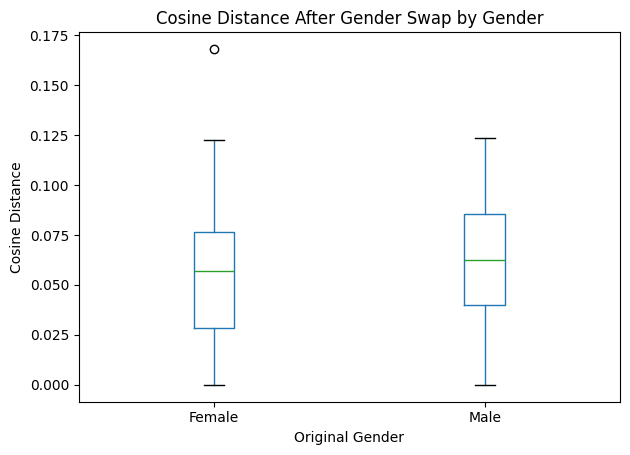

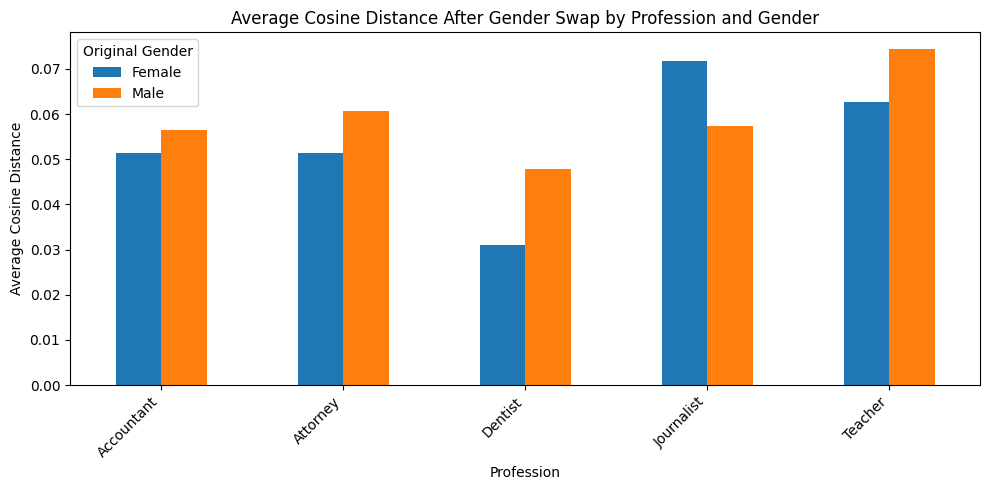

,Profession,Gender,Mean cosine distance,Std. dev.,N
0,accountant,female,0.051,0.029,7
1,accountant,male,0.056,0.030,7
2,attorney,female,0.051,0.029,30
3,attorney,male,0.061,0.027,30
4,dentist,female,0.031,0.031,10
5,dentist,male,0.048,0.039,10
6,journalist,female,0.072,0.037,13
7,journalist,male,0.057,0.034,13
8,teacher,female,0.063,0.036,14
9,teacher,male,0.074,0.034,14


In [ ]:
# Optional: make labels prettier
plot_df = embedding_distance_df.copy()
plot_df["gender_label"] = plot_df["gender_label"].str.capitalize()
plot_df["selected_profession"] = plot_df["selected_profession"].str.replace("_", " ").str.title()

# Boxplot: cosine distance by gender
plt.figure(figsize=(7, 5))

plot_df.boxplot(
    column="distance",
    by="gender_label",
    grid=False
)

plt.title("Cosine Distance After Gender Swap by Gender")
plt.suptitle("")
plt.xlabel("Original Gender")
plt.ylabel("Cosine Distance")
plt.tight_layout()
plt.show()

# Bar chart: average cosine distance by profession and gender
summary_plot = (
    plot_df
    .groupby(["selected_profession", "gender_label"])["distance"]
    .mean()
    .reset_index()
)

pivot_plot = summary_plot.pivot(
    index="selected_profession",
    columns="gender_label",
    values="distance"
)

ax = pivot_plot.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Cosine Distance After Gender Swap by Profession and Gender")
plt.xlabel("Profession")
plt.ylabel("Average Cosine Distance")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Original Gender")
plt.tight_layout()
plt.show()

#Rapport-tabel med afrundede værdier
report_table = embedding_summary.copy()

report_table["mean"] = report_table["mean"].round(3)
report_table["std"] = report_table["std"].round(3)

report_table = report_table.rename(columns={
    "selected_profession": "Profession",
    "gender_label": "Gender",
    "mean": "Mean cosine distance",
    "std": "Std. dev.",
    "count": "N"
})

display(report_table)

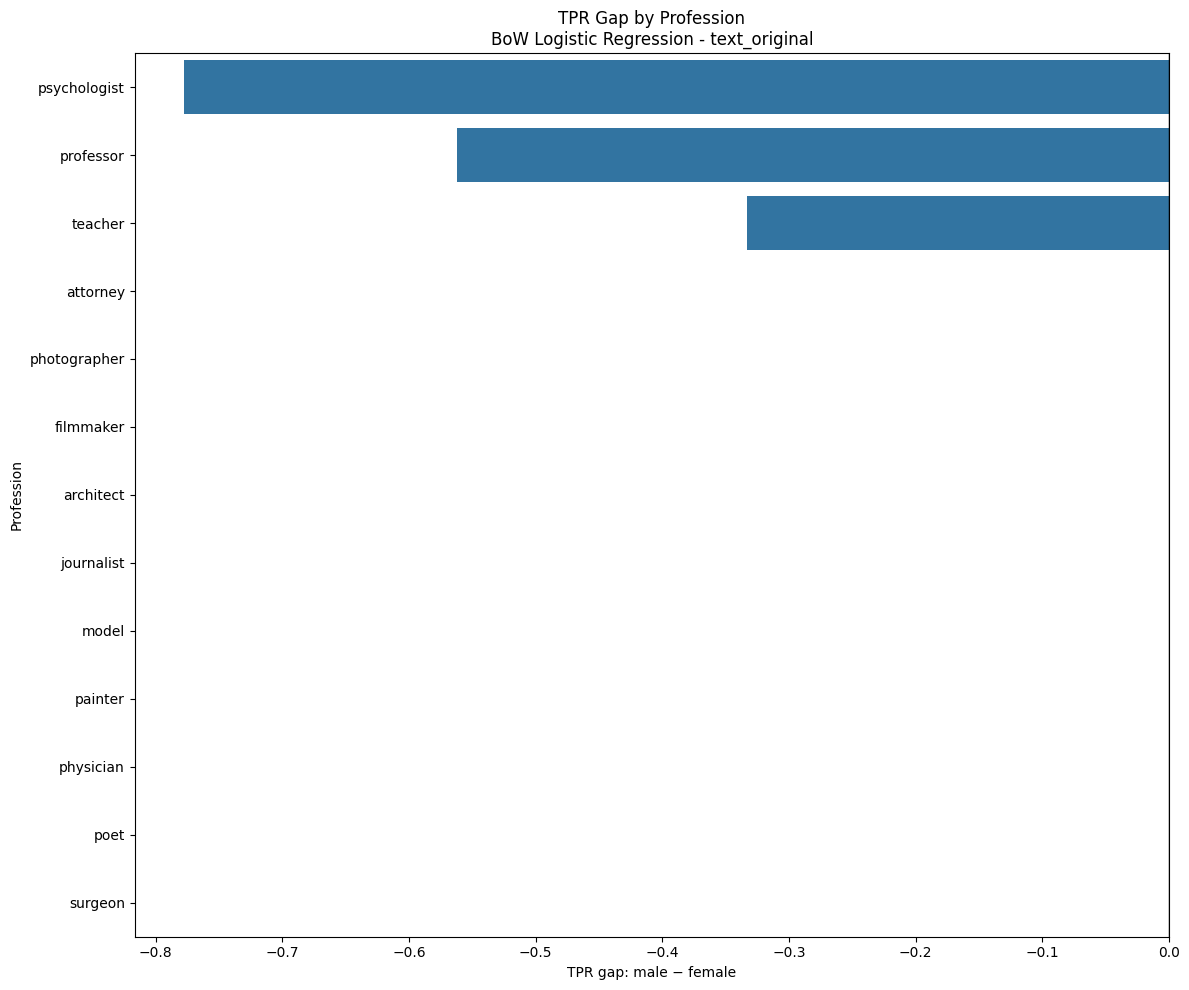

In [ ]:
# ===== Vælg model =====
for version in ["text_original", "text_swapped", "text_neutral"]:
    model_key = ("BoW_LogisticRegression", version)
    preds = bow_results[model_key]["preds"][balanced_idx]

# Lav dataframe
df = balanced_eval_df.copy()

# Tilføj predictions
df["preds"] = preds

# ===== Beregn TPR pr profession og køn =====

rows = []

for profession in df["profession_label"].unique():

    prof_df = df[df["profession_label"] == profession]

    for gender in ["male", "female"]:

        gender_df = prof_df[prof_df["gender_label"] == gender]

        if len(gender_df) == 0:
            continue

        y_true = gender_df["profession_label"]
        y_pred = gender_df["preds"]

        tpr = recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )

        rows.append({
            "profession": profession,
            "gender": gender,
            "macro_tpr": tpr
        })

# Konverter til dataframe
profession_results = pd.DataFrame(rows)

# ===== Beregn fairness gaps =====

profession_gap_df = profession_results.pivot_table(
    index="profession",
    columns="gender",
    values="macro_tpr"
).reset_index()

profession_gap_df["tpr_gap_male_minus_female"] = (
    profession_gap_df["male"] - profession_gap_df["female"]
)

# Sortér
profession_gap_df = profession_gap_df.sort_values(
    "tpr_gap_male_minus_female",
    ascending=True
)

# ===== Plot =====

plt.figure(figsize=(12, 10))

sns.barplot(
    data=profession_gap_df,
    x="tpr_gap_male_minus_female",
    y="profession",
    orient="h"
)

plt.axvline(0, color="black", linewidth=1)

plt.title(
    "TPR Gap by Profession\nBoW Logistic Regression - text_original"
)

plt.xlabel("TPR gap: male − female")
plt.ylabel("Profession")

plt.yticks(fontsize=10)

plt.tight_layout()
plt.show()

## **6.5. INSPECT CHANGED PREDICTIONS**
Select cases where the model prediction changed after gender swapping or gender neutralization

In [ ]:
list(llm_results.keys())

[('OpenAI_LLM_zero_shot', 'text_original'),
 ('OpenAI_LLM_zero_shot', 'text_swapped'),
 ('OpenAI_LLM_zero_shot', 'text_neutral'),
 ('OpenAI_LLM_cot', 'text_original'),
 ('OpenAI_LLM_cot', 'text_swapped'),
 ('OpenAI_LLM_cot', 'text_neutral')]

In [ ]:
changed_cases_all = []

for model_label in ["OpenAI_LLM_zero_shot", "OpenAI_LLM_cot"]:
    llm_compare = llm_results[(model_label, "text_original")].copy()

    for version in ["text_original", "text_swapped", "text_neutral"]:
        df_version = llm_results[(model_label, version)]
        llm_compare[f"pred_{version}"] = df_version[f"llm_pred_{version}"].values

    llm_compare["changed_after_swap"] = (
        llm_compare["pred_text_original"] != llm_compare["pred_text_swapped"]
    )

    llm_compare["changed_after_neutral"] = (
        llm_compare["pred_text_original"] != llm_compare["pred_text_neutral"]
    )

    temp = llm_compare[
        (llm_compare["changed_after_swap"]) |
        (llm_compare["changed_after_neutral"])
    ][[
        TEXT_COL,
        "gender_label",
        "profession_label",
        "pred_text_original",
        "pred_text_swapped",
        "pred_text_neutral",
        "changed_after_swap",
        "changed_after_neutral"
    ]].copy()

    temp["model"] = model_label
    changed_cases_all.append(temp)

changed_cases = pd.concat(changed_cases_all, ignore_index=True)

changed_cases.head(20)

,hard_text,gender_label,profession_label,pred_text_original,pred_text_swapped,pred_text_neutral,changed_after_swap,changed_after_neutral,model
0,He holds an MSc in Palliative Care from Cardif...,male,surgeon,physician,surgeon,physician,True,False,OpenAI_LLM_zero_shot
1,He was recently selected by ABC television to ...,male,professor,rapper,journalist,rapper,True,False,OpenAI_LLM_zero_shot
2,She is also a faculty member of the Governor’s...,female,professor,teacher,professor,teacher,True,False,OpenAI_LLM_zero_shot
3,He is a researcher associated with the LIRCES ...,male,psychologist,psychologist,professor,psychologist,True,False,OpenAI_LLM_zero_shot
4,She is also a co-author of this recently condu...,female,professor,professor,professor,psychologist,False,True,OpenAI_LLM_zero_shot
5,He has a broad background in communication and...,male,professor,professor,professor,dietitian,False,True,OpenAI_LLM_zero_shot
6,He majors in the Environmental Design and Info...,male,professor,professor,professor,architect,False,True,OpenAI_LLM_zero_shot
7,With expertise in personal and career developm...,female,psychologist,professor,personal_trainer,psychologist,True,True,OpenAI_LLM_zero_shot
8,She received her MFA in Communication Arts fro...,female,professor,painter,photographer,painter,True,False,OpenAI_LLM_zero_shot
9,He is currently under contract with Facts on F...,male,professor,professor,journalist,professor,True,False,OpenAI_LLM_zero_shot


# **7. MODEL COMPARISON**

##**7.1. COMBINED RESULTS**

In [ ]:
all_results = pd.concat([bow_fairness, llm_fairness], ignore_index=True)
all_results

,model,text_version,gender,n,accuracy,macro_tpr,macro_f1
0,BoW_LogisticRegression,text_original,female,365,0.720548,0.515926,0.519151
1,BoW_LogisticRegression,text_original,male,435,0.737931,0.603538,0.609553
2,BoW_LogisticRegression,text_swapped,female,365,0.720548,0.498883,0.506144
3,BoW_LogisticRegression,text_swapped,male,435,0.744828,0.621858,0.624466
4,BoW_LogisticRegression,text_neutral,female,365,0.715068,0.496217,0.508183
5,BoW_LogisticRegression,text_neutral,male,435,0.744828,0.621882,0.619361
6,OpenAI_LLM_zero_shot,text_original,female,365,0.750685,0.661405,0.632103
7,OpenAI_LLM_zero_shot,text_original,male,435,0.816092,0.781541,0.740865
8,OpenAI_LLM_zero_shot,text_swapped,female,365,0.758904,0.660582,0.634060
9,OpenAI_LLM_zero_shot,text_swapped,male,435,0.813793,0.782405,0.745112


##**7.1.1 COMBINED RESULTS (+F1)**

In [ ]:
# Samlet accuracy + macro F1 for alle modeller
all_f1 = pd.concat([bow_f1_df, llm_f1_df], ignore_index=True)

all_f1["text_version"] = all_f1["text_version"].replace({
    "text_original": "Original",
    "text_swapped": "Swapped",
    "text_neutral": "Neutral"
})

all_f1_pivot = all_f1.pivot_table(
    index=["model", "text_version"],
    values=["accuracy", "macro_f1", "macro_tpr"]
).round(3)

all_f1_pivot

accuracy  macro_f1  macro_tpr
model                    text_version                               
BoW_LogReg_BalancedTrain Neutral          0.716     0.596      0.578
                         Original         0.711     0.588      0.572
                         Swapped          0.718     0.605      0.585
BoW_LogisticRegression   Neutral          0.731     0.615      0.603
                         Original         0.730     0.606      0.598
                         Swapped          0.734     0.618      0.604
OpenAI_LLM_cot           Neutral          0.754     0.693      0.757
                         Original         0.749     0.715      0.773
                         Swapped          0.738     0.703      0.748
OpenAI_LLM_zero_shot     Neutral          0.782     0.733      0.806
                         Original         0.786     0.739      0.809
                         Swapped          0.789     0.737      0.808

## **7.2. BALANCED RESULTS USING EXISTING PREDICTIONS**

In [ ]:
# === 7.1A BALANCED RESULTS USING EXISTING PREDICTIONS ===
# This creates the same result table as 7.1, but evaluated on a gender-balanced subset.
# It does NOT call the OpenAI API again.

BALANCED_EVAL_SIZE = None  # None = use max possible balanced size

# Use only rows where LLM predictions exist
llm_reference_df = llm_results[("OpenAI_LLM_cot", "text_original")]
available_idx = llm_reference_df.index

balanced_base_df = test_df.loc[available_idx].copy()

# Find max possible balanced size
female_df = balanced_base_df[balanced_base_df["gender_label"] == "female"]
male_df = balanced_base_df[balanced_base_df["gender_label"] == "male"]

if BALANCED_EVAL_SIZE is None:
    n_per_gender = min(len(female_df), len(male_df))
else:
    n_per_gender = min(BALANCED_EVAL_SIZE // 2, len(female_df), len(male_df))

balanced_eval_df = pd.concat([
    female_df.sample(n=n_per_gender, random_state=RANDOM_SEED),
    male_df.sample(n=n_per_gender, random_state=RANDOM_SEED)
]).sample(frac=1, random_state=RANDOM_SEED)

balanced_idx = balanced_eval_df.index.to_numpy()

print("Balanced evaluation set:")
display(balanced_eval_df["gender_label"].value_counts())

# BoW fairness on balanced evaluation set
balanced_bow_fairness = []

for (model_label, version), result in bow_results.items():
    preds_balanced = result["preds"][balanced_idx]

    balanced_bow_fairness.append(
        evaluate_by_gender(
            balanced_eval_df,
            preds_balanced,
            model_label,
            version
        )
    )

balanced_bow_fairness = pd.concat(balanced_bow_fairness, ignore_index=True)

# LLM fairness on balanced evaluation set
balanced_llm_fairness = []

for (model_label, version), df_version in llm_results.items():
    pred_col = f"llm_pred_{version}"

    df_balanced_version = df_version.loc[balanced_idx].copy()
    preds_balanced = df_balanced_version[pred_col].values

    balanced_llm_fairness.append(
        evaluate_by_gender(
            df_balanced_version,
            preds_balanced,
            model_label,
            version
        )
    )

balanced_llm_fairness = pd.concat(balanced_llm_fairness, ignore_index=True)

# Combine into one table
balanced_all_results = pd.concat(
    [balanced_bow_fairness, balanced_llm_fairness],
    ignore_index=True
)

balanced_all_results

Balanced evaluation set:


,count
gender_label,
male,365
female,365


,model,text_version,gender,n,accuracy,macro_tpr,macro_f1
0,BoW_LogisticRegression,text_original,female,365,0.720548,0.515926,0.519151
1,BoW_LogisticRegression,text_original,male,365,0.742466,0.603706,0.599136
2,BoW_LogisticRegression,text_swapped,female,365,0.720548,0.498883,0.506144
3,BoW_LogisticRegression,text_swapped,male,365,0.750685,0.620459,0.615257
4,BoW_LogisticRegression,text_neutral,female,365,0.715068,0.496217,0.508183
5,BoW_LogisticRegression,text_neutral,male,365,0.750685,0.619971,0.613259
6,OpenAI_LLM_zero_shot,text_original,female,365,0.750685,0.661405,0.632103
7,OpenAI_LLM_zero_shot,text_original,male,365,0.824658,0.793556,0.754289
8,OpenAI_LLM_zero_shot,text_swapped,female,365,0.758904,0.660582,0.634060
9,OpenAI_LLM_zero_shot,text_swapped,male,365,0.821918,0.792295,0.758927


##**7.3. COMPARE FAIRNESS GAP**

In [ ]:
fairness_gaps = calculate_fairness_gaps(all_results)

fairness_gaps

,model,text_version,accuracy_gap_male_minus_female,macro_tpr_gap_male_minus_female,macro_f1_gap_male_minus_female
0,BoW_LogisticRegression,text_neutral,0.029759,0.125664,0.111179
1,BoW_LogisticRegression,text_original,0.017383,0.087612,0.090403
2,BoW_LogisticRegression,text_swapped,0.024280,0.122975,0.118322
3,OpenAI_LLM_cot,text_neutral,0.000598,0.037222,0.021530
4,OpenAI_LLM_cot,text_original,0.026673,0.083293,0.060873
5,OpenAI_LLM_cot,text_swapped,0.026138,0.092261,0.069187
6,OpenAI_LLM_zero_shot,text_neutral,0.038356,0.094332,0.086427
7,OpenAI_LLM_zero_shot,text_original,0.065407,0.120135,0.108762
8,OpenAI_LLM_zero_shot,text_swapped,0.054889,0.121822,0.111052


### **7.3.1. Fairness Gaps**

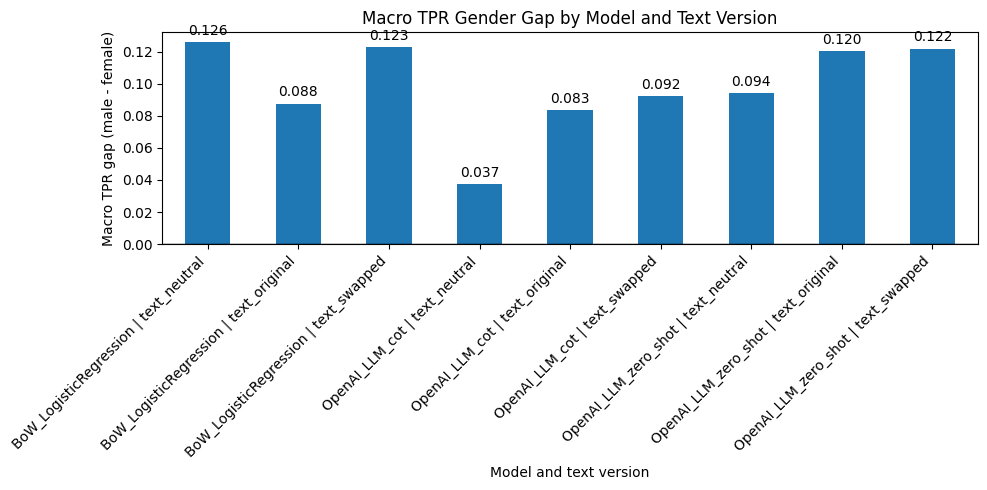

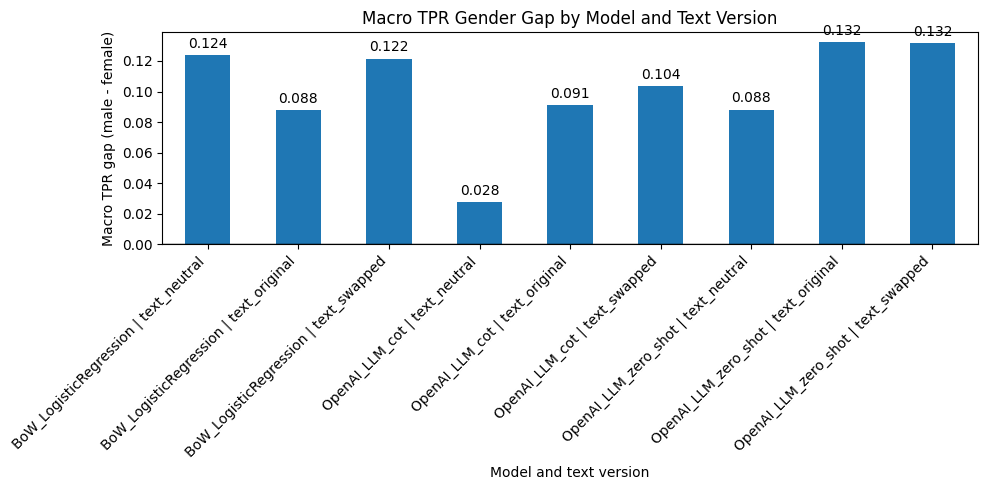

In [ ]:
plot_fairness_gaps(fairness_gaps)

# === CREATE BALANCED FAIRNESS GAPS ===

balanced_fairness_gaps = calculate_fairness_gaps(balanced_all_results)

balanced_fairness_gaps
plot_fairness_gaps(balanced_fairness_gaps)


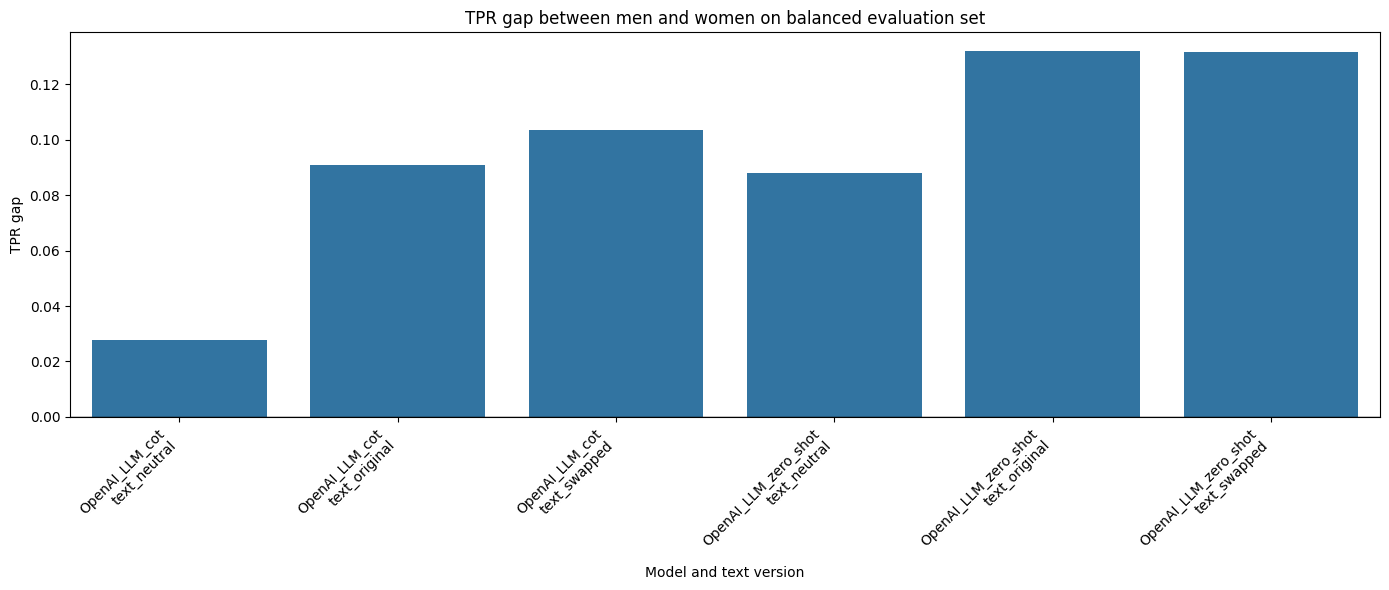

In [ ]:
# Vælg de modeller og tekstversioner du vil plotte
models_to_plot = [
    "Logistic Regression",
    "OpenAI_LLM_zero_shot",
    "OpenAI_LLM_cot"
]

versions_to_plot = [
    "text_original",
    "text_swapped",
    "text_neutral"
]

# Filtrér fairness gaps
plot_df = balanced_fairness_gaps[
    balanced_fairness_gaps["model"].isin(models_to_plot) &
    balanced_fairness_gaps["text_version"].isin(versions_to_plot)
].copy()

# Kombinér model og tekstversion på x-aksen
plot_df["model_version"] = plot_df["model"] + "\n" + plot_df["text_version"]

plt.figure(figsize=(14, 6))

sns.barplot(
    data=plot_df,
    x="model_version",
    y="macro_tpr_gap_male_minus_female", # Corrected column name
    errorbar=None
)

plt.axhline(0, color="black", linewidth=1)

plt.title("TPR gap between men and women on balanced evaluation set")
plt.xlabel("Model and text version")
plt.ylabel("TPR gap")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

##**7.4. COMPARE PREDICTION CHANGE RATES**

In [ ]:
change_rates = pd.concat(
    [bow_change_rates_all, llm_change_rates_all],
    ignore_index=True
)

change_rates

,model,metric,value
0,BoW_LogisticRegression,Original → Swapped,0.03625
1,BoW_LogisticRegression,Original → Neutral,0.03375
2,OpenAI_LLM_zero_shot,Original → Swapped,0.03500
3,OpenAI_LLM_zero_shot,Original → Neutral,0.03250
4,OpenAI_LLM_cot,Original → Swapped,0.07875
5,OpenAI_LLM_cot,Original → Neutral,0.07500


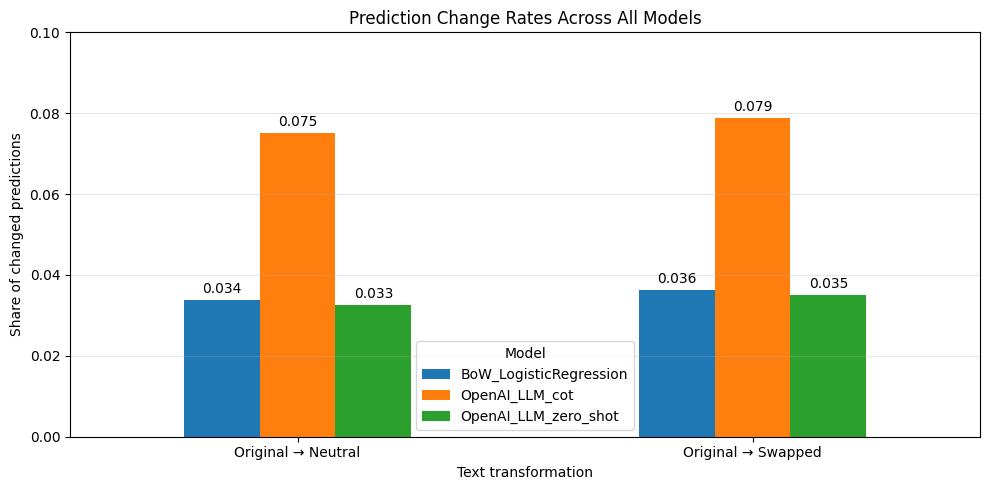

In [ ]:
def plot_model_change_rates(change_rates):
    pivot = change_rates.pivot(
        index="metric",
        columns="model",
        values="value"
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(10, 5)
    )

    plt.title("Prediction Change Rates Across All Models")
    plt.xlabel("Text transformation")
    plt.ylabel("Share of changed predictions")
    plt.ylim(0, max(0.10, change_rates["value"].max() + 0.02))
    plt.xticks(rotation=0)
    plt.legend(title="Model")
    plt.grid(axis="y", alpha=0.3)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3)

    plt.tight_layout()
    plt.show()

plot_model_change_rates(change_rates)

---
# **RODDEBUTIK :)**



## **VISUALIZE BOW PREDICTIONS BY GENDER**

In [ ]:
import matplotlib.pyplot as plt

def plot_predicted_professions_by_gender(test_df, bow_preds, text_version):
    """
    Creates a bar chart showing how many male and female biographies
    the BoW model predicted for each profession.
    """

    plot_df = test_df.copy()
    plot_df["predicted_profession"] = bow_preds[text_version]

    counts = (
        plot_df
        .groupby(["predicted_profession", "gender_label"])
        .size()
        .unstack(fill_value=0)
        .reindex(LABEL_SET, fill_value=0)
    )

    # Ensure both gender columns exist
    for gender in ["female", "male"]:
        if gender not in counts.columns:
            counts[gender] = 0

    counts = counts[["female", "male"]]

    ax = counts.plot(
        kind="bar",
        figsize=(16, 6),
        width=0.8
    )

    plt.title(f"BoW predicted professions by gender: {text_version}")
    plt.xlabel("Predicted profession")
    plt.ylabel("Number of biographies")
    plt.xticks(rotation=75, ha="right")
    plt.legend(title="Original gender label")
    plt.tight_layout()
    plt.show()

In [ ]:
for version in ["text_original", "text_swapped", "text_neutral"]:
    plot_predicted_professions_by_gender(test_df, bow_preds, version)

NameError: name 'bow_preds' is not defined

## **PLOT: CHANGE RATE (BoW)**

In [ ]:
def plot_change_per_profession_side_by_side(bow_compare):
    df = bow_compare.copy()

    # Calculate change rates per predicted profession
    swap_rates = (
        df.groupby("pred_text_original")["changed_after_swap"]
        .mean()
        .reindex(LABEL_SET, fill_value=0)
    )

    neutral_rates = (
        df.groupby("pred_text_original")["changed_after_neutral"]
        .mean()
        .reindex(LABEL_SET, fill_value=0)
    )

    x = np.arange(len(LABEL_SET))
    width = 0.4

    plt.figure(figsize=(16, 6))

    # Side-by-side bars
    plt.bar(x - width/2, swap_rates, width=width, label="Swap (he↔she)")
    plt.bar(x + width/2, neutral_rates, width=width, label="Neutral (they)")

    # Labels and layout
    plt.xticks(x, LABEL_SET, rotation=75, ha="right")
    plt.ylabel("Change rate")
    plt.xlabel("Predicted profession")
    plt.title("BoW: Change rate per profession")

    plt.legend()
    plt.tight_layout()
    plt.show()


# Run plot
plot_change_per_profession_side_by_side(bow_compare)

## **CONFUSION MATRIX VISUALIZATION**
Builds and displays a confusion matrix for multi-class classification.

* Rows = true labels
* Columns = predicted labels

In [ ]:
def show_confusion_matrix(df, y_pred, title="Confusion matrix"):
    y_true = df["profession_label"].values

    cm = confusion_matrix(y_true, y_pred, labels=LABEL_SET)
    cm_df = pd.DataFrame(cm, index=LABEL_SET, columns=LABEL_SET)

    print(title)
    return cm_df

cm_bow_original = show_confusion_matrix(test_df, bow_preds["text_original"], "BoW original")
cm_bow_original

In [ ]:
# Plot BoW Naive Bayes Change Rate
def plot_prediction_shift(shift_df, model_name="BoW_NaiveBayes"):
    df = shift_df.copy()

    df["metric"] = df["metric"].replace({
        "swap_change_rate": "Original → Swapped",
        "neutral_change_rate": "Original → Neutral"
    })

    ax = df.plot(
        x="metric",
        y="value",
        kind="bar",
        legend=False,
        figsize=(7, 5)
    )

    plt.title(f"{model_name}: Prediction Change Rate")
    plt.xlabel("Text transformation")
    plt.ylabel("Share of changed predictions")
    plt.ylim(0, 1)
    plt.xticks(rotation=0)
    plt.grid(axis="y", alpha=0.3)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3)

    plt.tight_layout()
    plt.show()

plot_prediction_shift(bow_change_rates_all[bow_change_rates_all["model"] == "BoW_NaiveBayes"], model_name="BoW_NaiveBayes")